# Mark Ayman

# Bank Term Deposit Subscription Prediction

**Author:** Mark Ayman  
**Objective:** to preform full Analysis using PYTHON

## Introduction

This notebook performs a full data analysis workflow
The goal of this analysis is to:
- Understand the dataset structure
- Clean and preprocess the data
- Perform exploratory data analysis (EDA)
- Identify patterns and trends
- Generate business insights

## import libraries

In [33]:
from google.colab import files
import math
import pickle
import kagglehub
import numpy as np
import pandas as pd
import seaborn as sns
import plotly.express as px
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.compose import ColumnTransformer
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix , mean_absolute_error, mean_squared_error, r2_score

## load dataset

In [2]:
# Local on collab
df = files.upload()

In [3]:
df = pd.read_csv("bank.csv", sep=";")

## Data Overview

In [4]:
df.shape

(4521, 17)

In [5]:
df.columns

Index(['age', 'job', 'marital', 'education', 'default', 'balance', 'housing',
       'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays',
       'previous', 'poutcome', 'y'],
      dtype='object')

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4521 entries, 0 to 4520
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        4521 non-null   int64 
 1   job        4521 non-null   object
 2   marital    4521 non-null   object
 3   education  4521 non-null   object
 4   default    4521 non-null   object
 5   balance    4521 non-null   int64 
 6   housing    4521 non-null   object
 7   loan       4521 non-null   object
 8   contact    4521 non-null   object
 9   day        4521 non-null   int64 
 10  month      4521 non-null   object
 11  duration   4521 non-null   int64 
 12  campaign   4521 non-null   int64 
 13  pdays      4521 non-null   int64 
 14  previous   4521 non-null   int64 
 15  poutcome   4521 non-null   object
 16  y          4521 non-null   object
dtypes: int64(7), object(10)
memory usage: 600.6+ KB


In [7]:
df.nunique()

,0
age,67
job,12
marital,3
education,4
default,2
balance,2353
housing,2
loan,2
contact,3
day,31


In [8]:
df.describe()

,age,balance,day,duration,campaign,pdays,previous
count,4521.000000,4521.000000,4521.000000,4521.000000,4521.000000,4521.000000,4521.000000
mean,41.170095,1422.657819,15.915284,263.961292,2.793630,39.766645,0.542579
std,10.576211,3009.638142,8.247667,259.856633,3.109807,100.121124,1.693562
min,19.000000,-3313.000000,1.000000,4.000000,1.000000,-1.000000,0.000000
25%,33.000000,69.000000,9.000000,104.000000,1.000000,-1.000000,0.000000
50%,39.000000,444.000000,16.000000,185.000000,2.000000,-1.000000,0.000000
75%,49.000000,1480.000000,21.000000,329.000000,3.000000,-1.000000,0.000000
max,87.000000,71188.000000,31.000000,3025.000000,50.000000,871.000000,25.000000


In [9]:
df.describe(include = 'O')

,job,marital,education,default,housing,loan,contact,month,poutcome,y
count,4521,4521,4521,4521,4521,4521,4521,4521,4521,4521
unique,12,3,4,2,2,2,3,12,4,2
top,management,married,secondary,no,yes,no,cellular,may,unknown,no
freq,969,2797,2306,4445,2559,3830,2896,1398,3705,4000


In [10]:
df.duplicated().sum()

np.int64(0)

In [11]:
df.isnull().sum()

,0
age,0
job,0
marital,0
education,0
default,0
balance,0
housing,0
loan,0
contact,0
day,0


### dentify Column Types

In [12]:
X = df
categorical_cols = X.select_dtypes(include=["object"]).columns
numerical_cols = X.select_dtypes(exclude=["object"]).columns

## Data Cleaning

In [13]:
df.replace("unknown", "No", inplace=True)

In [14]:
df['y'] = df['y'].map({"yes": 1, "no": 0})

## Data Visualization

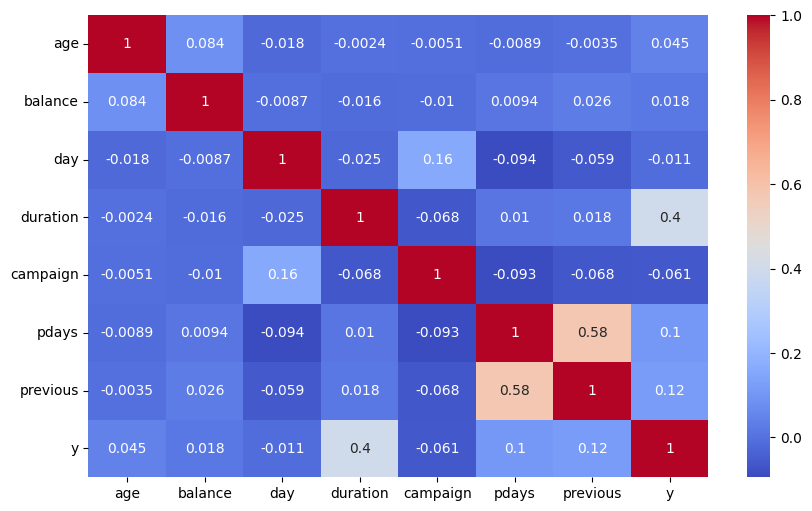

In [15]:
plt.figure(figsize=(10,6))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm')
plt.show()

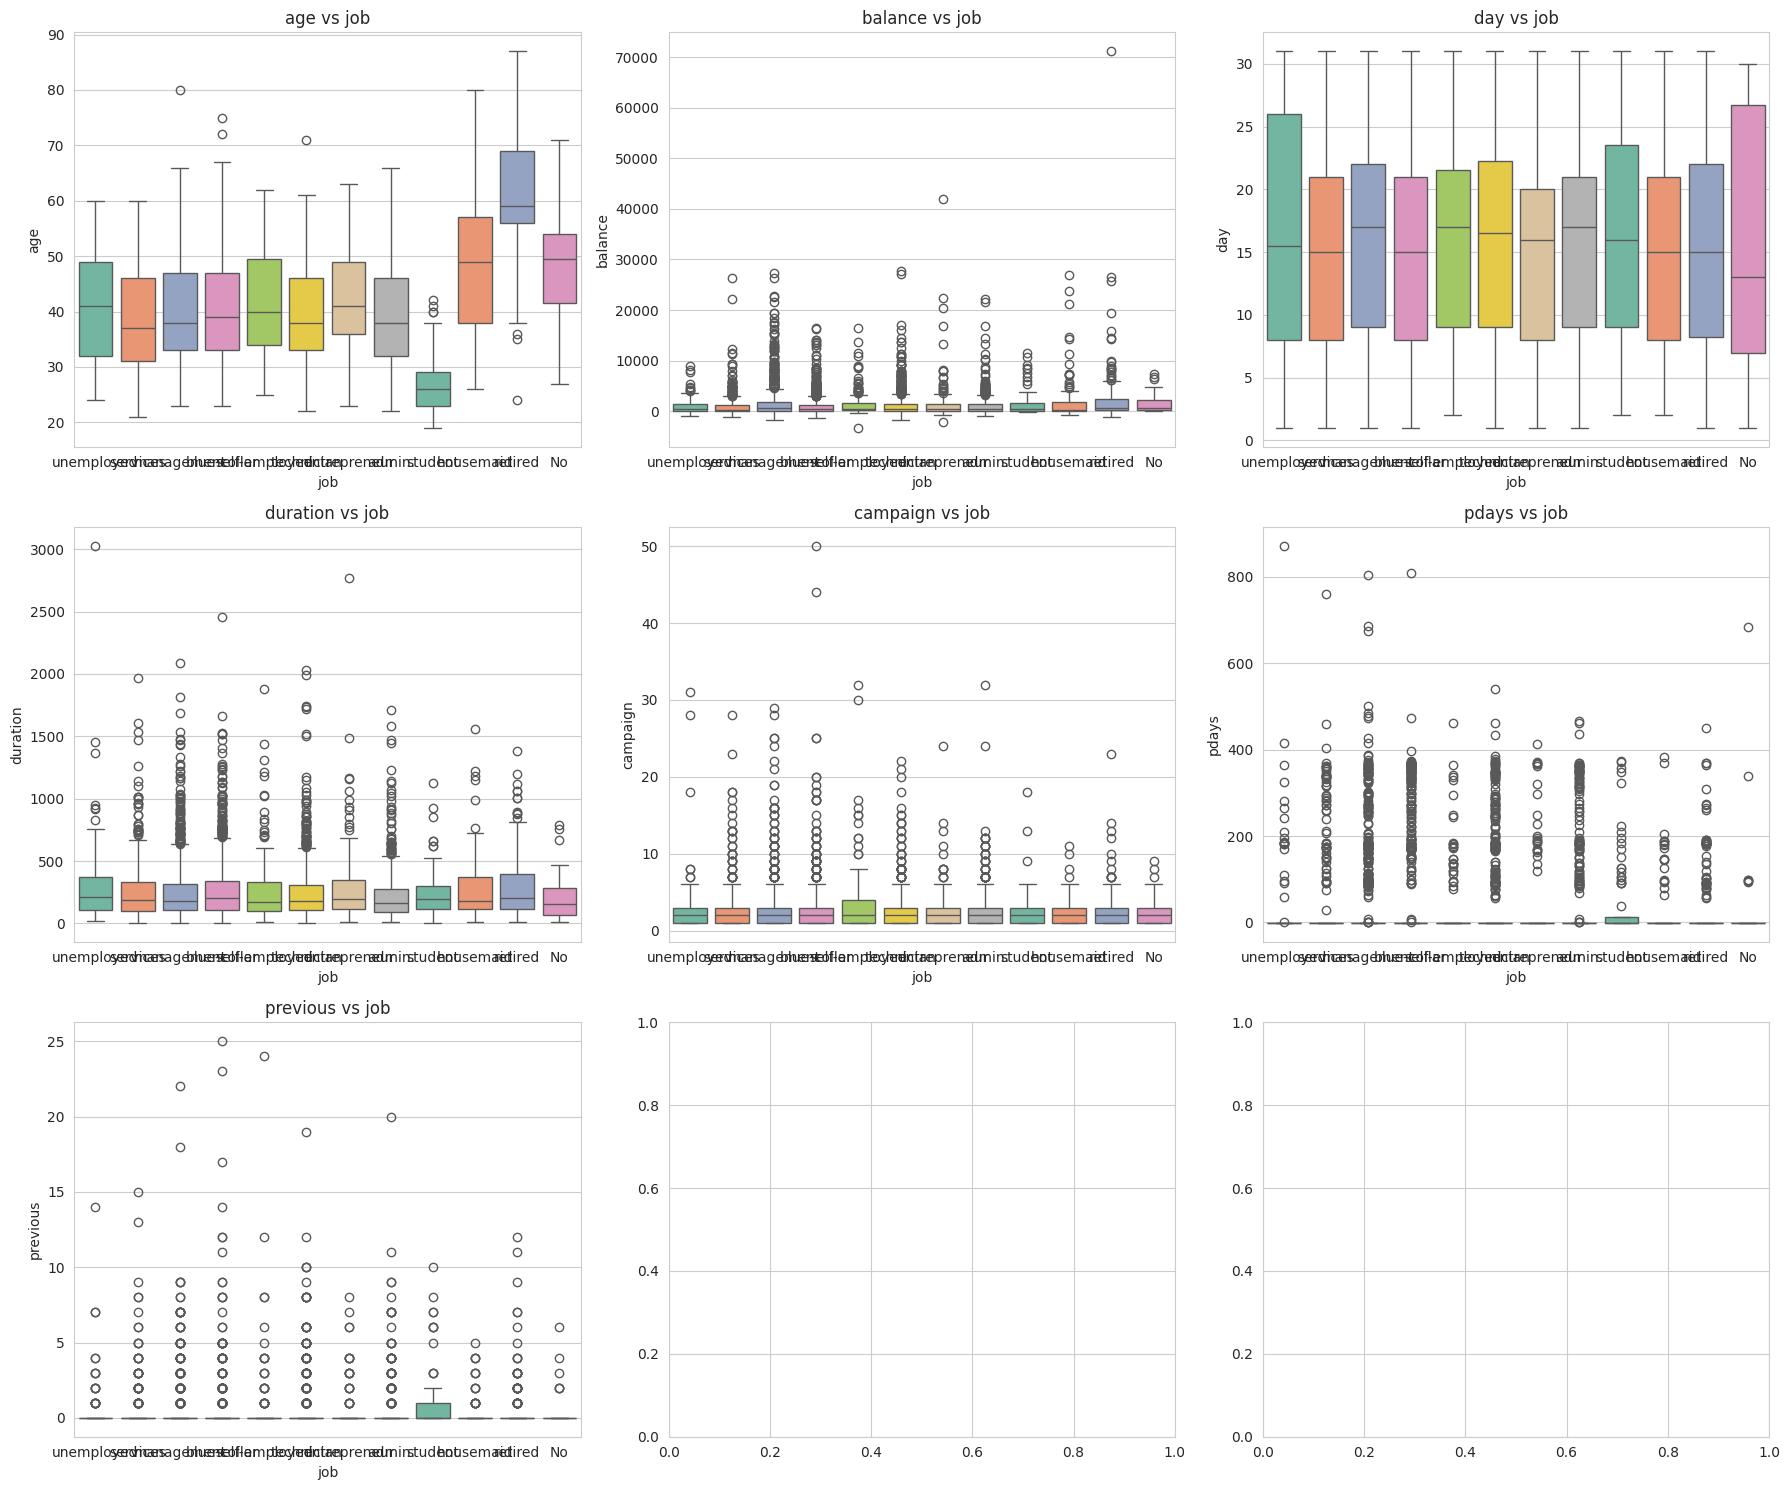

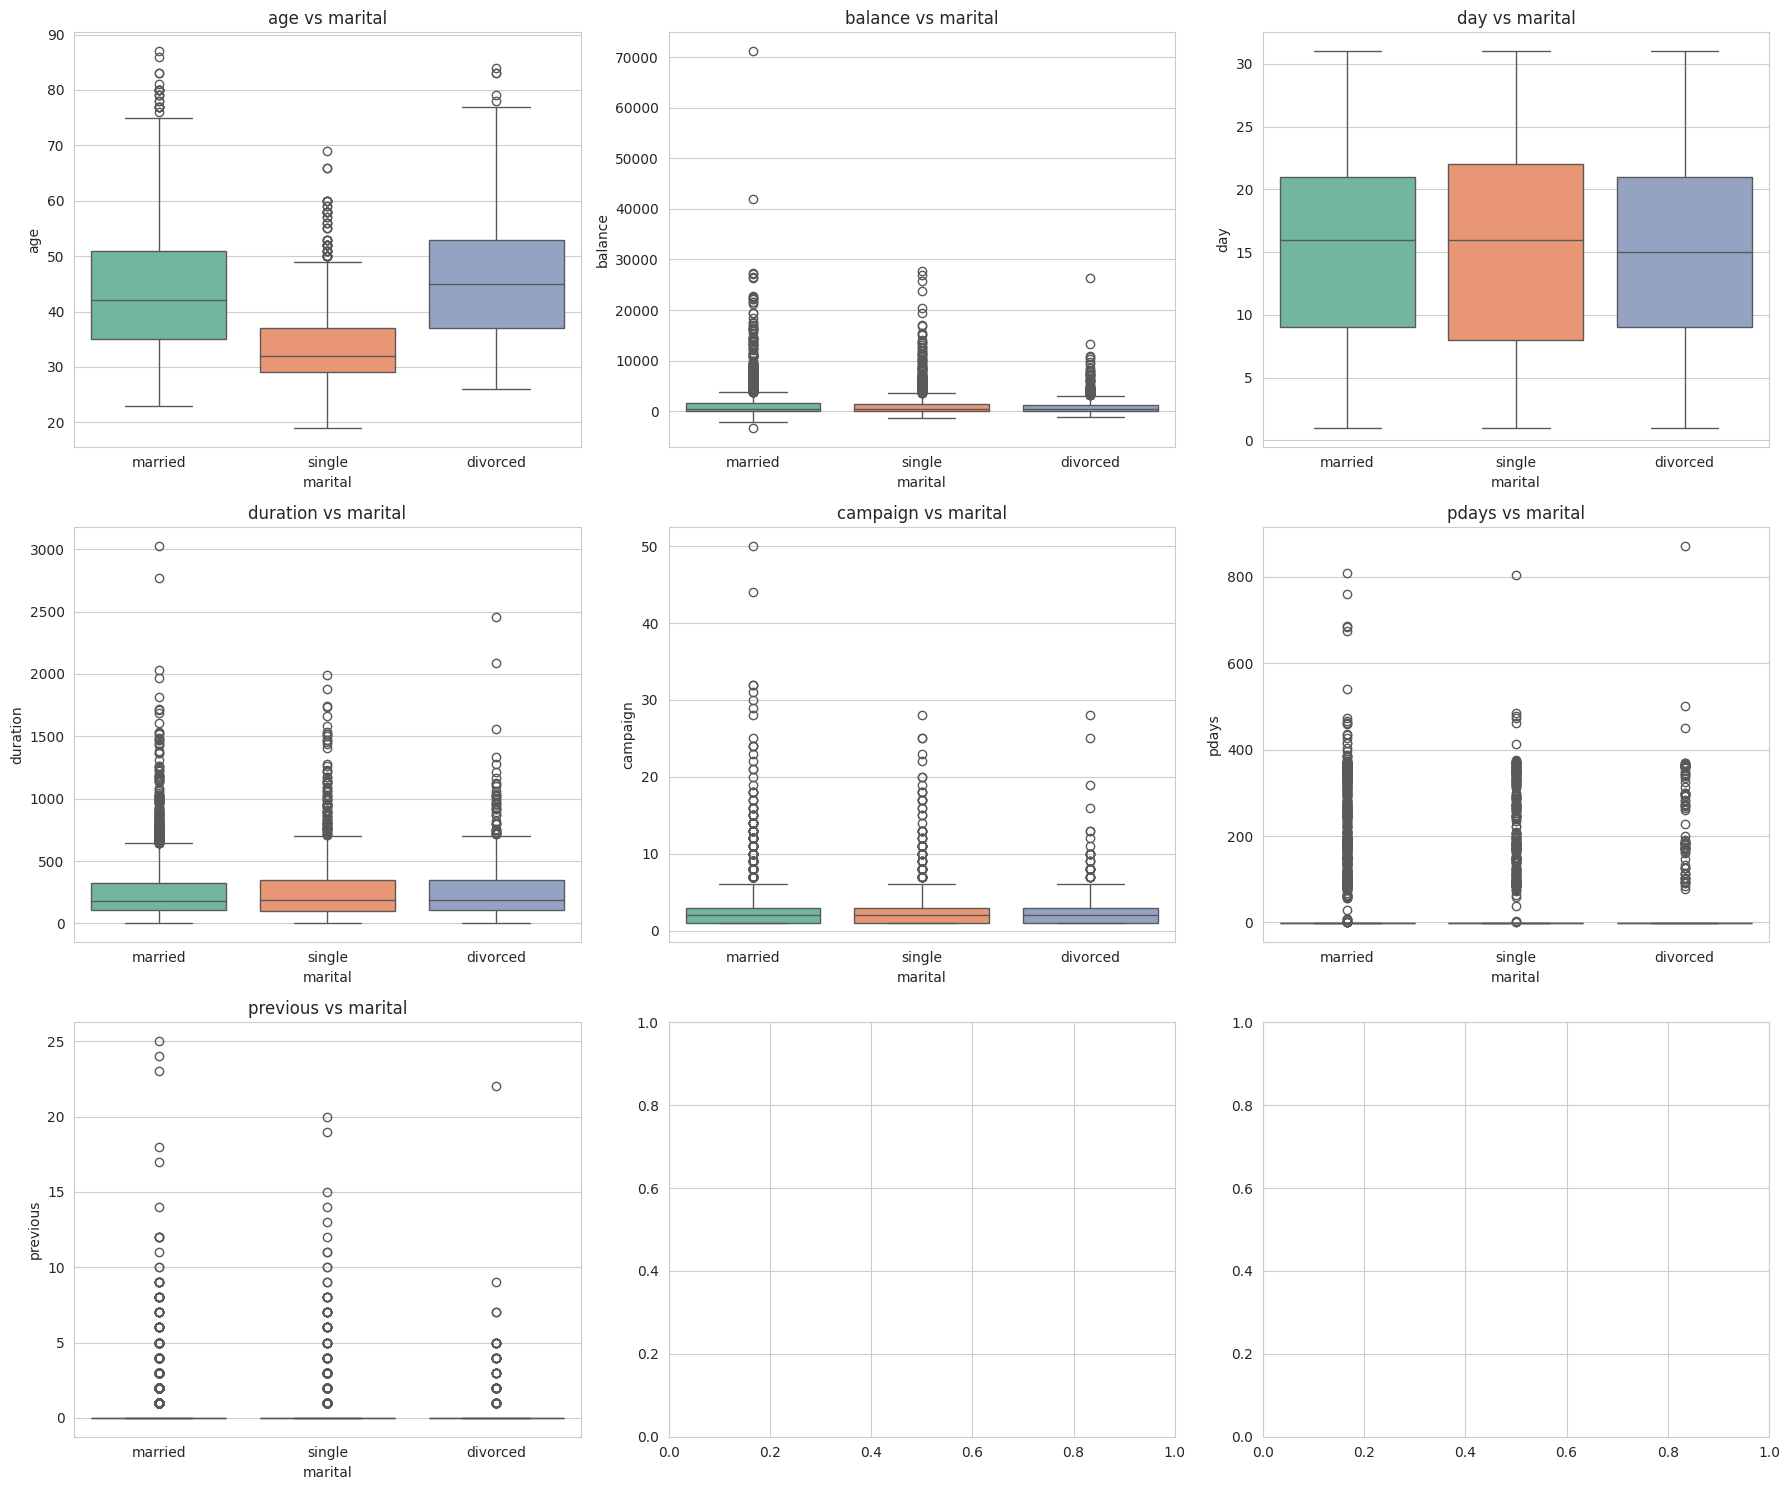

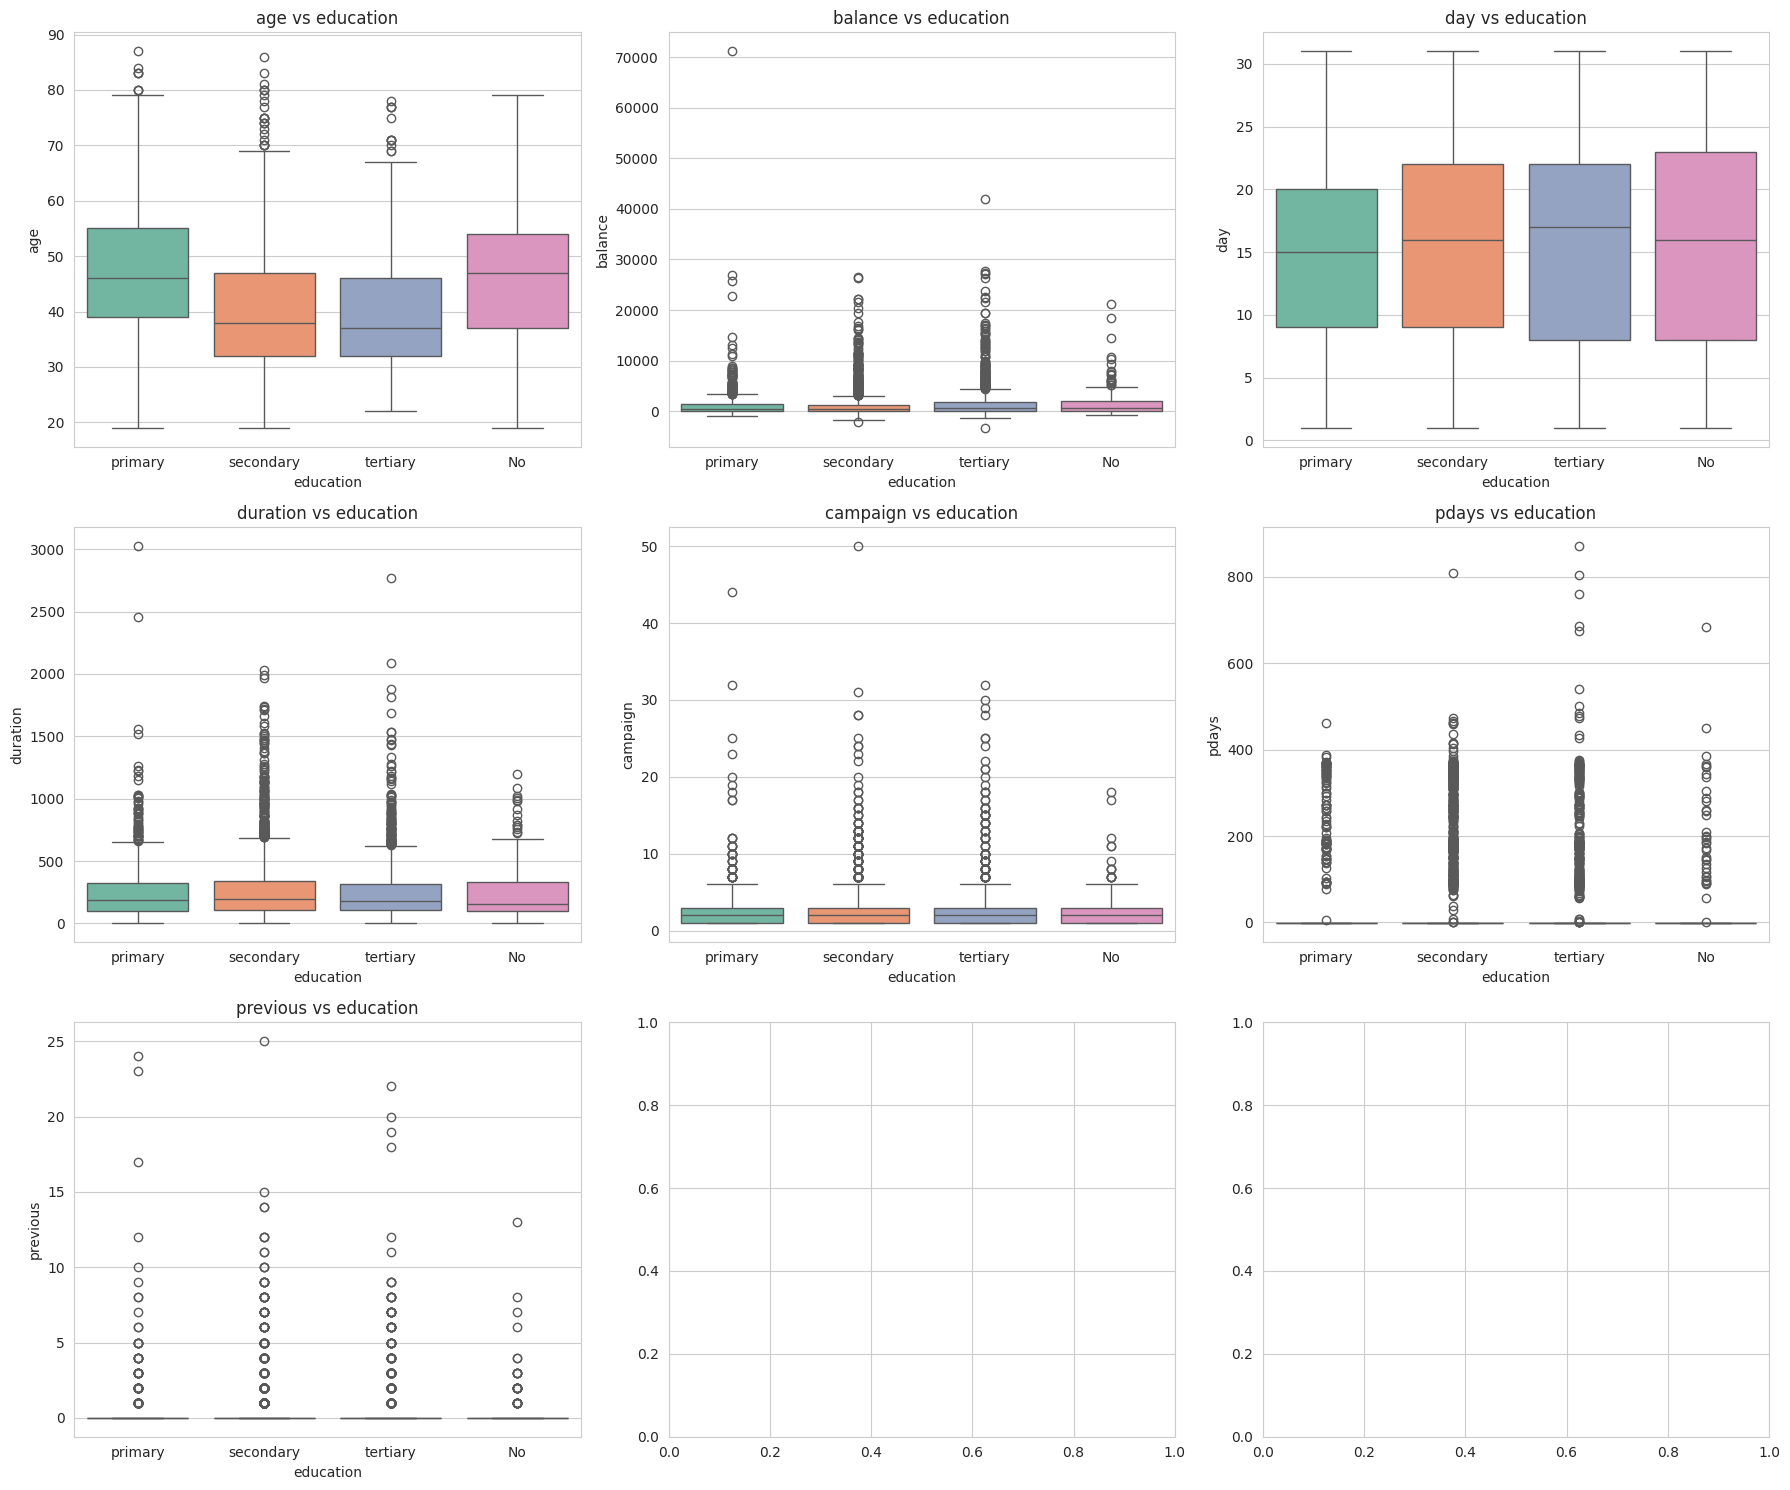

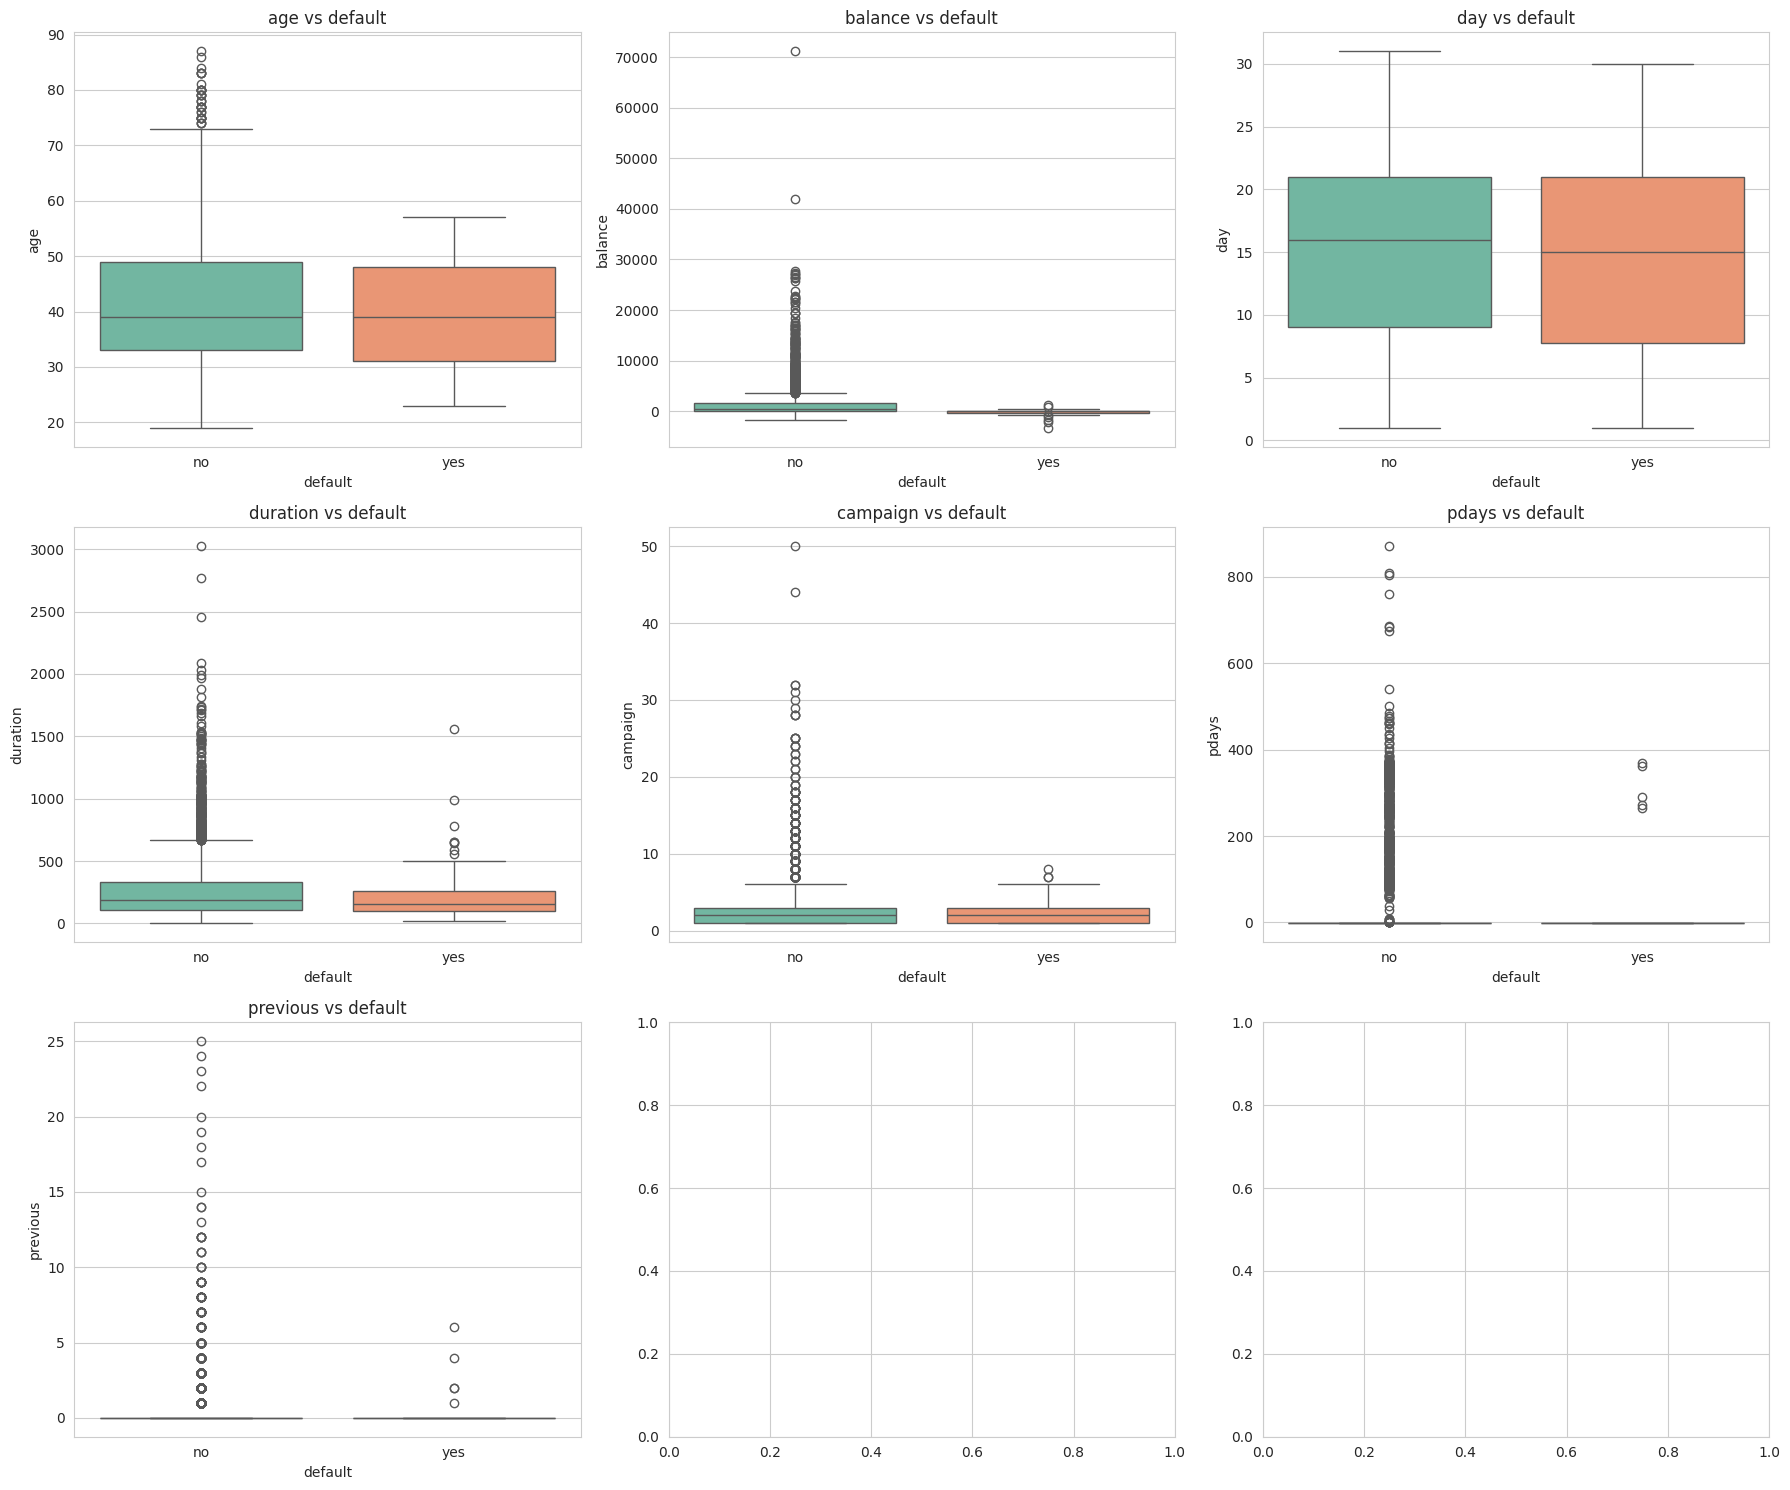

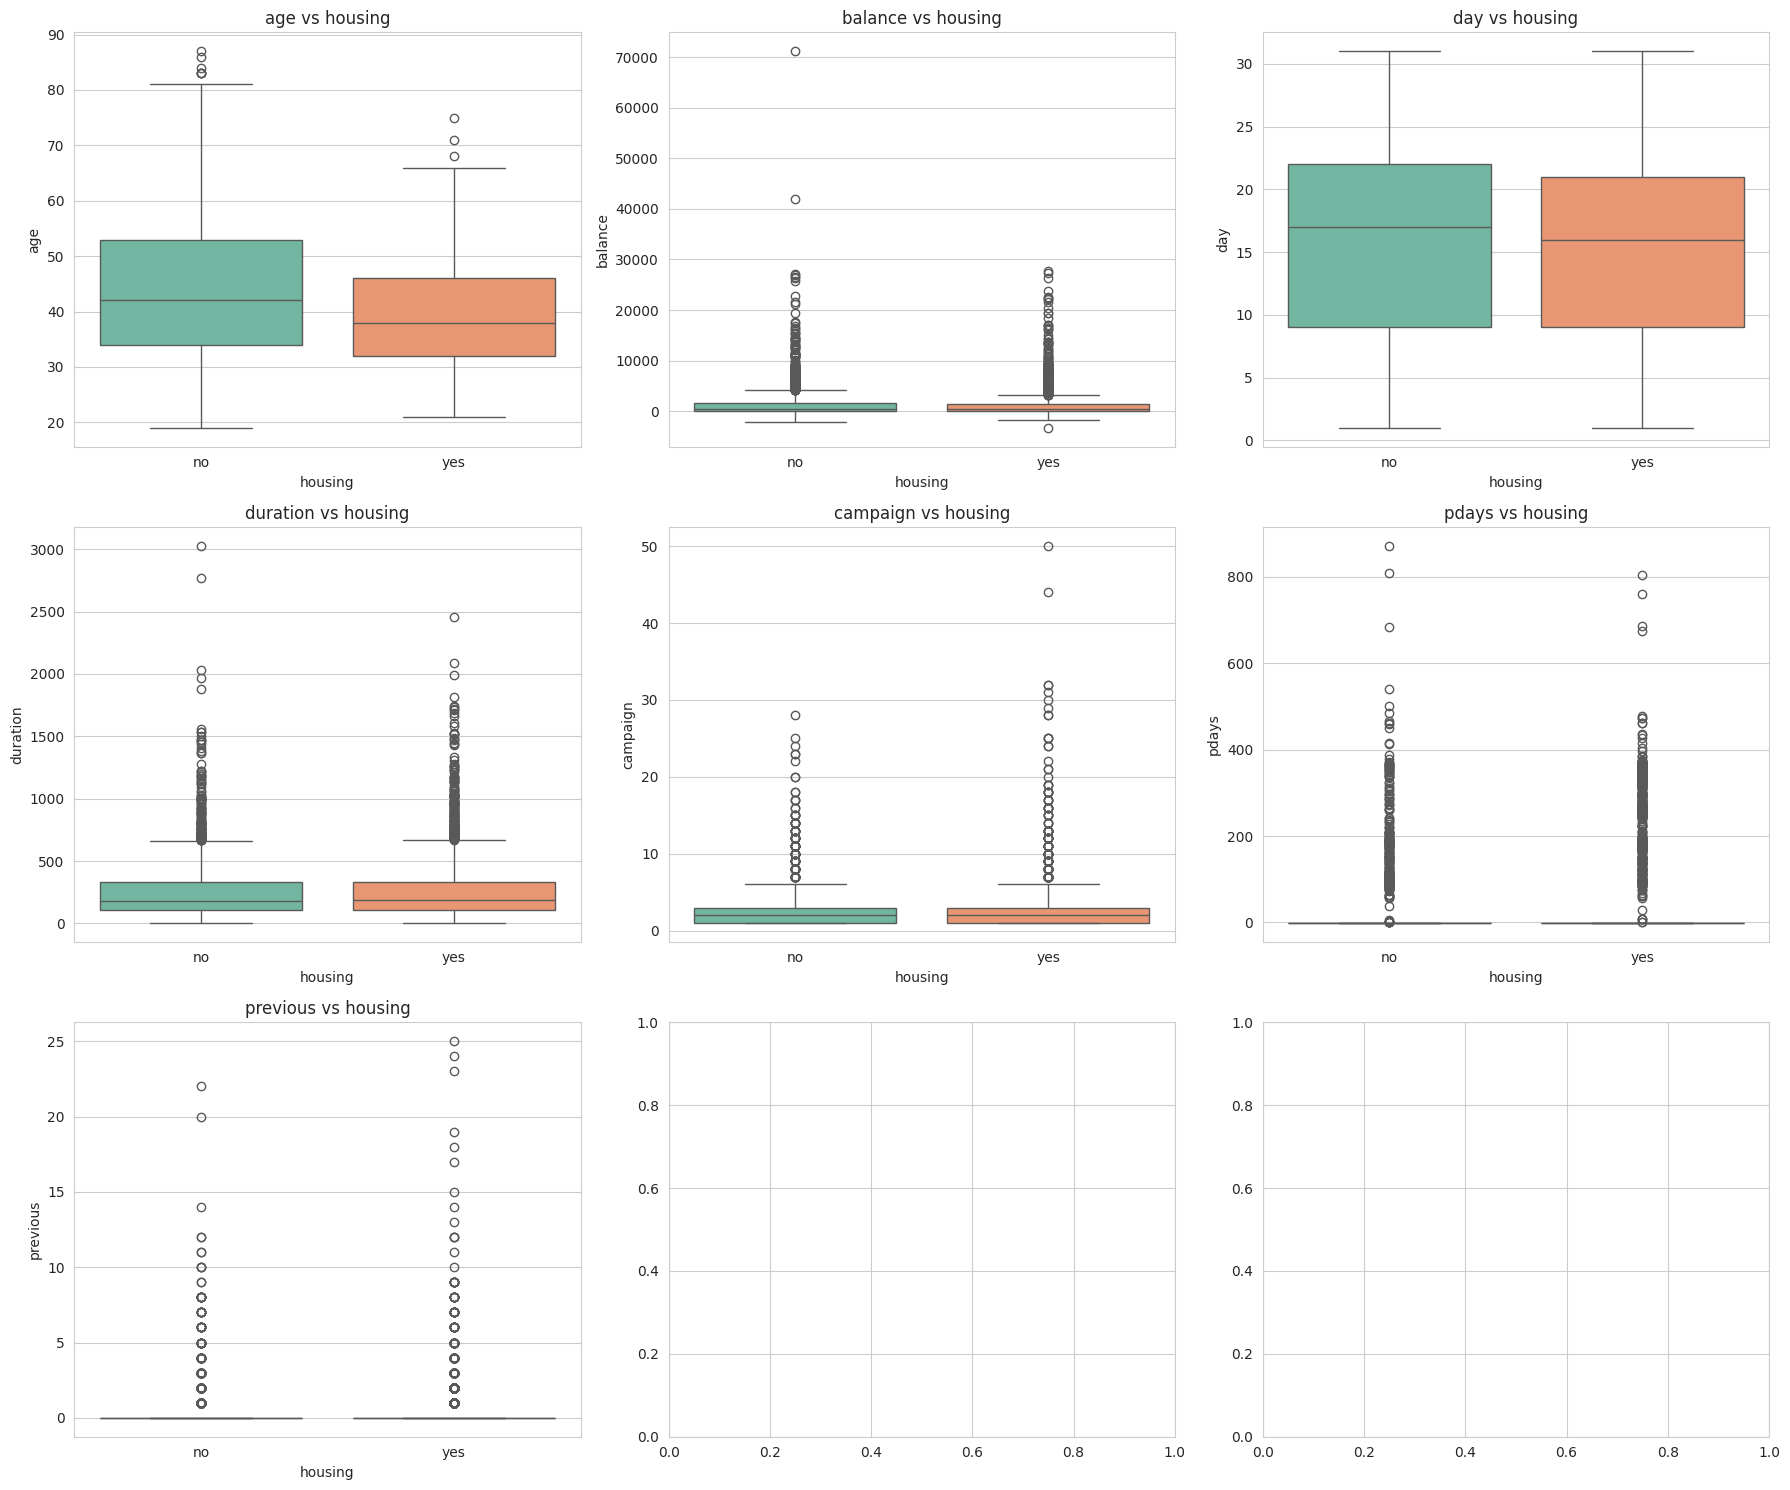

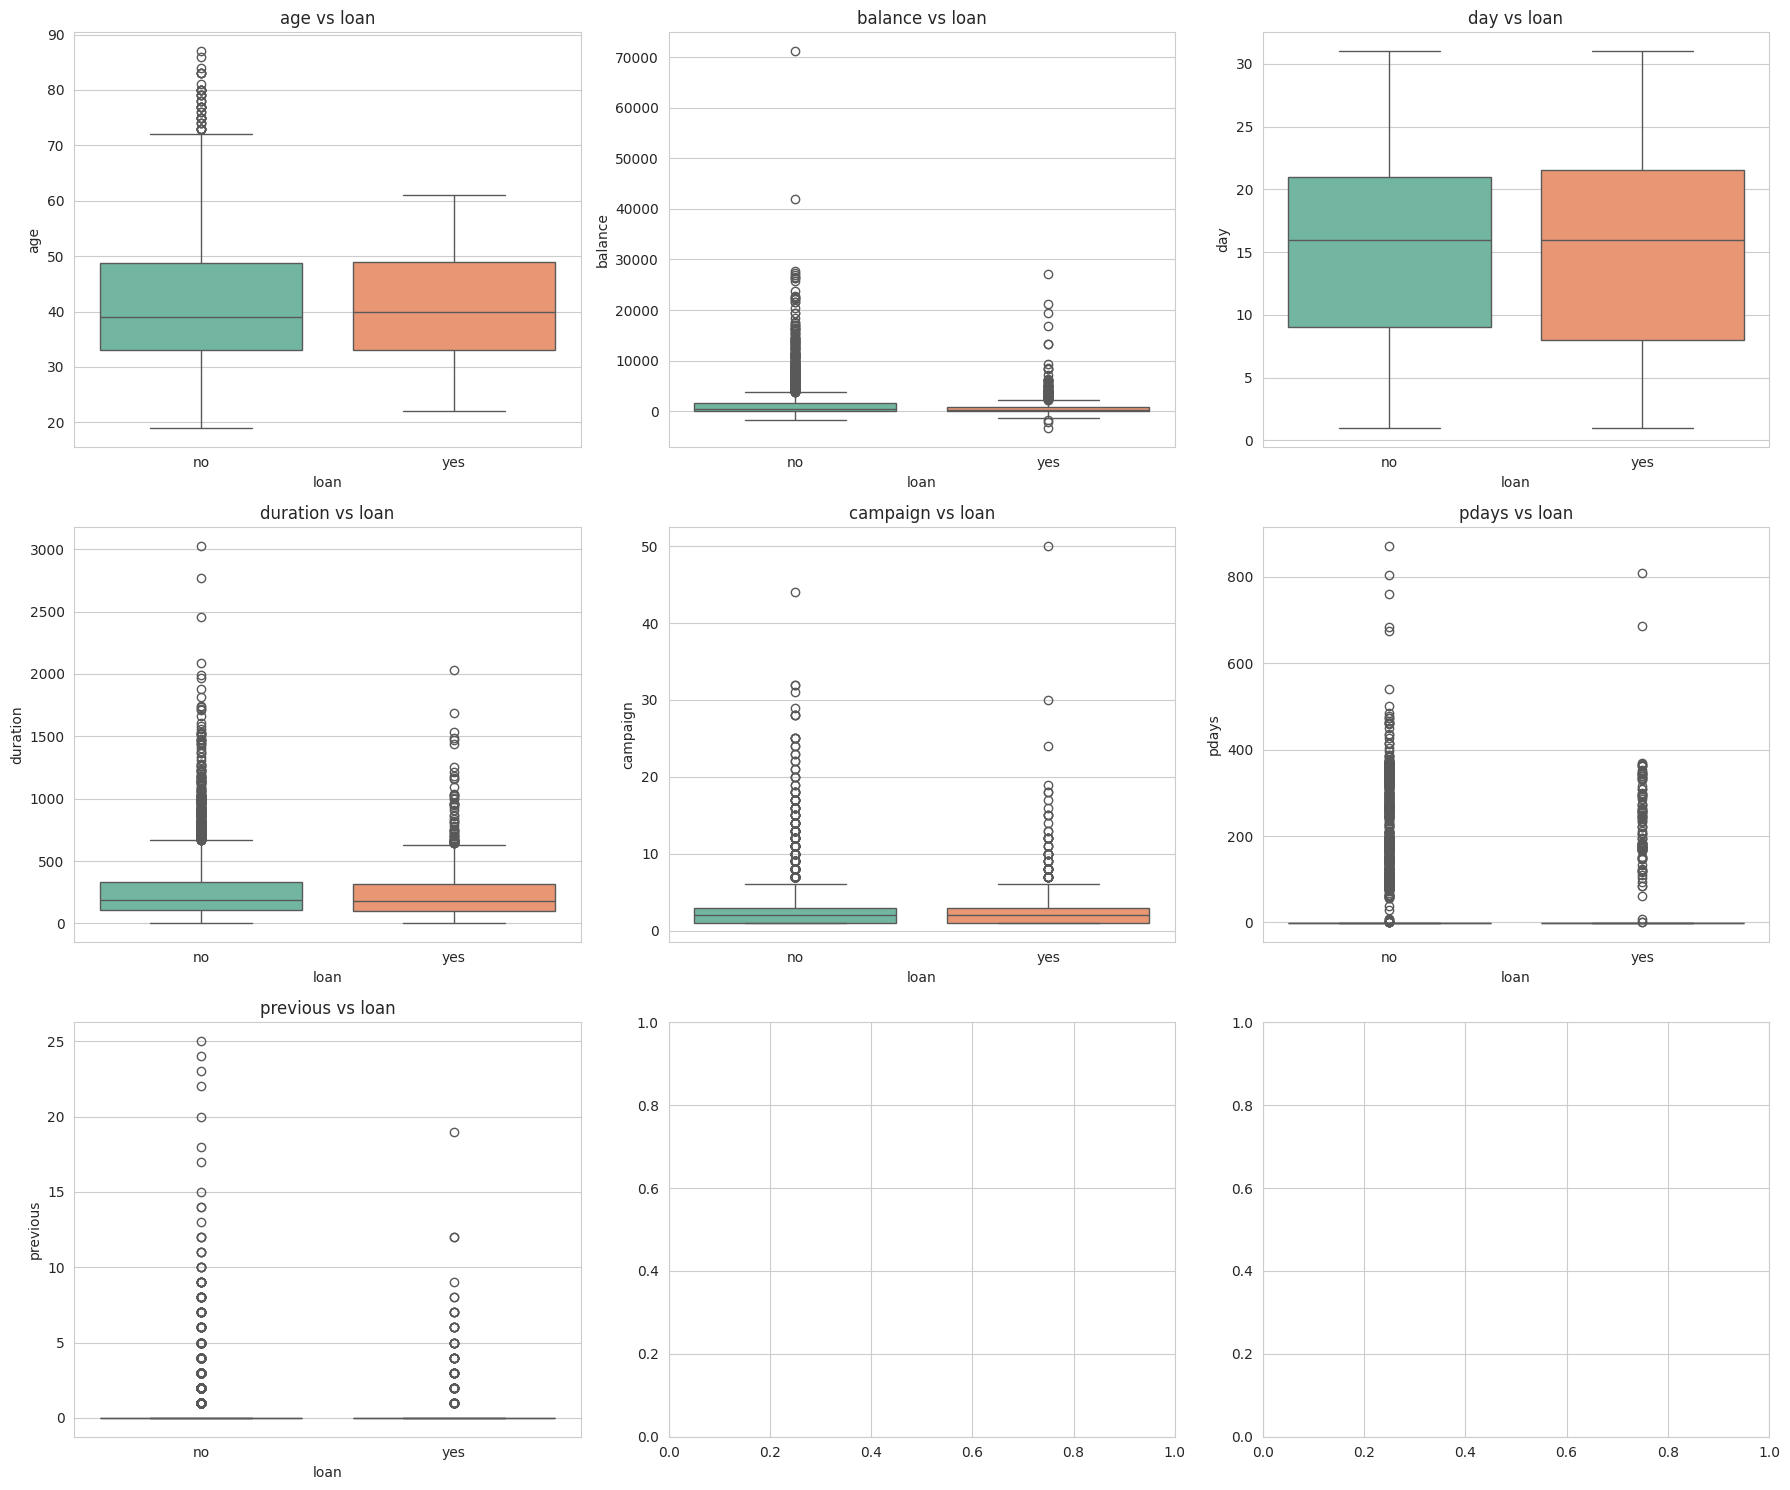

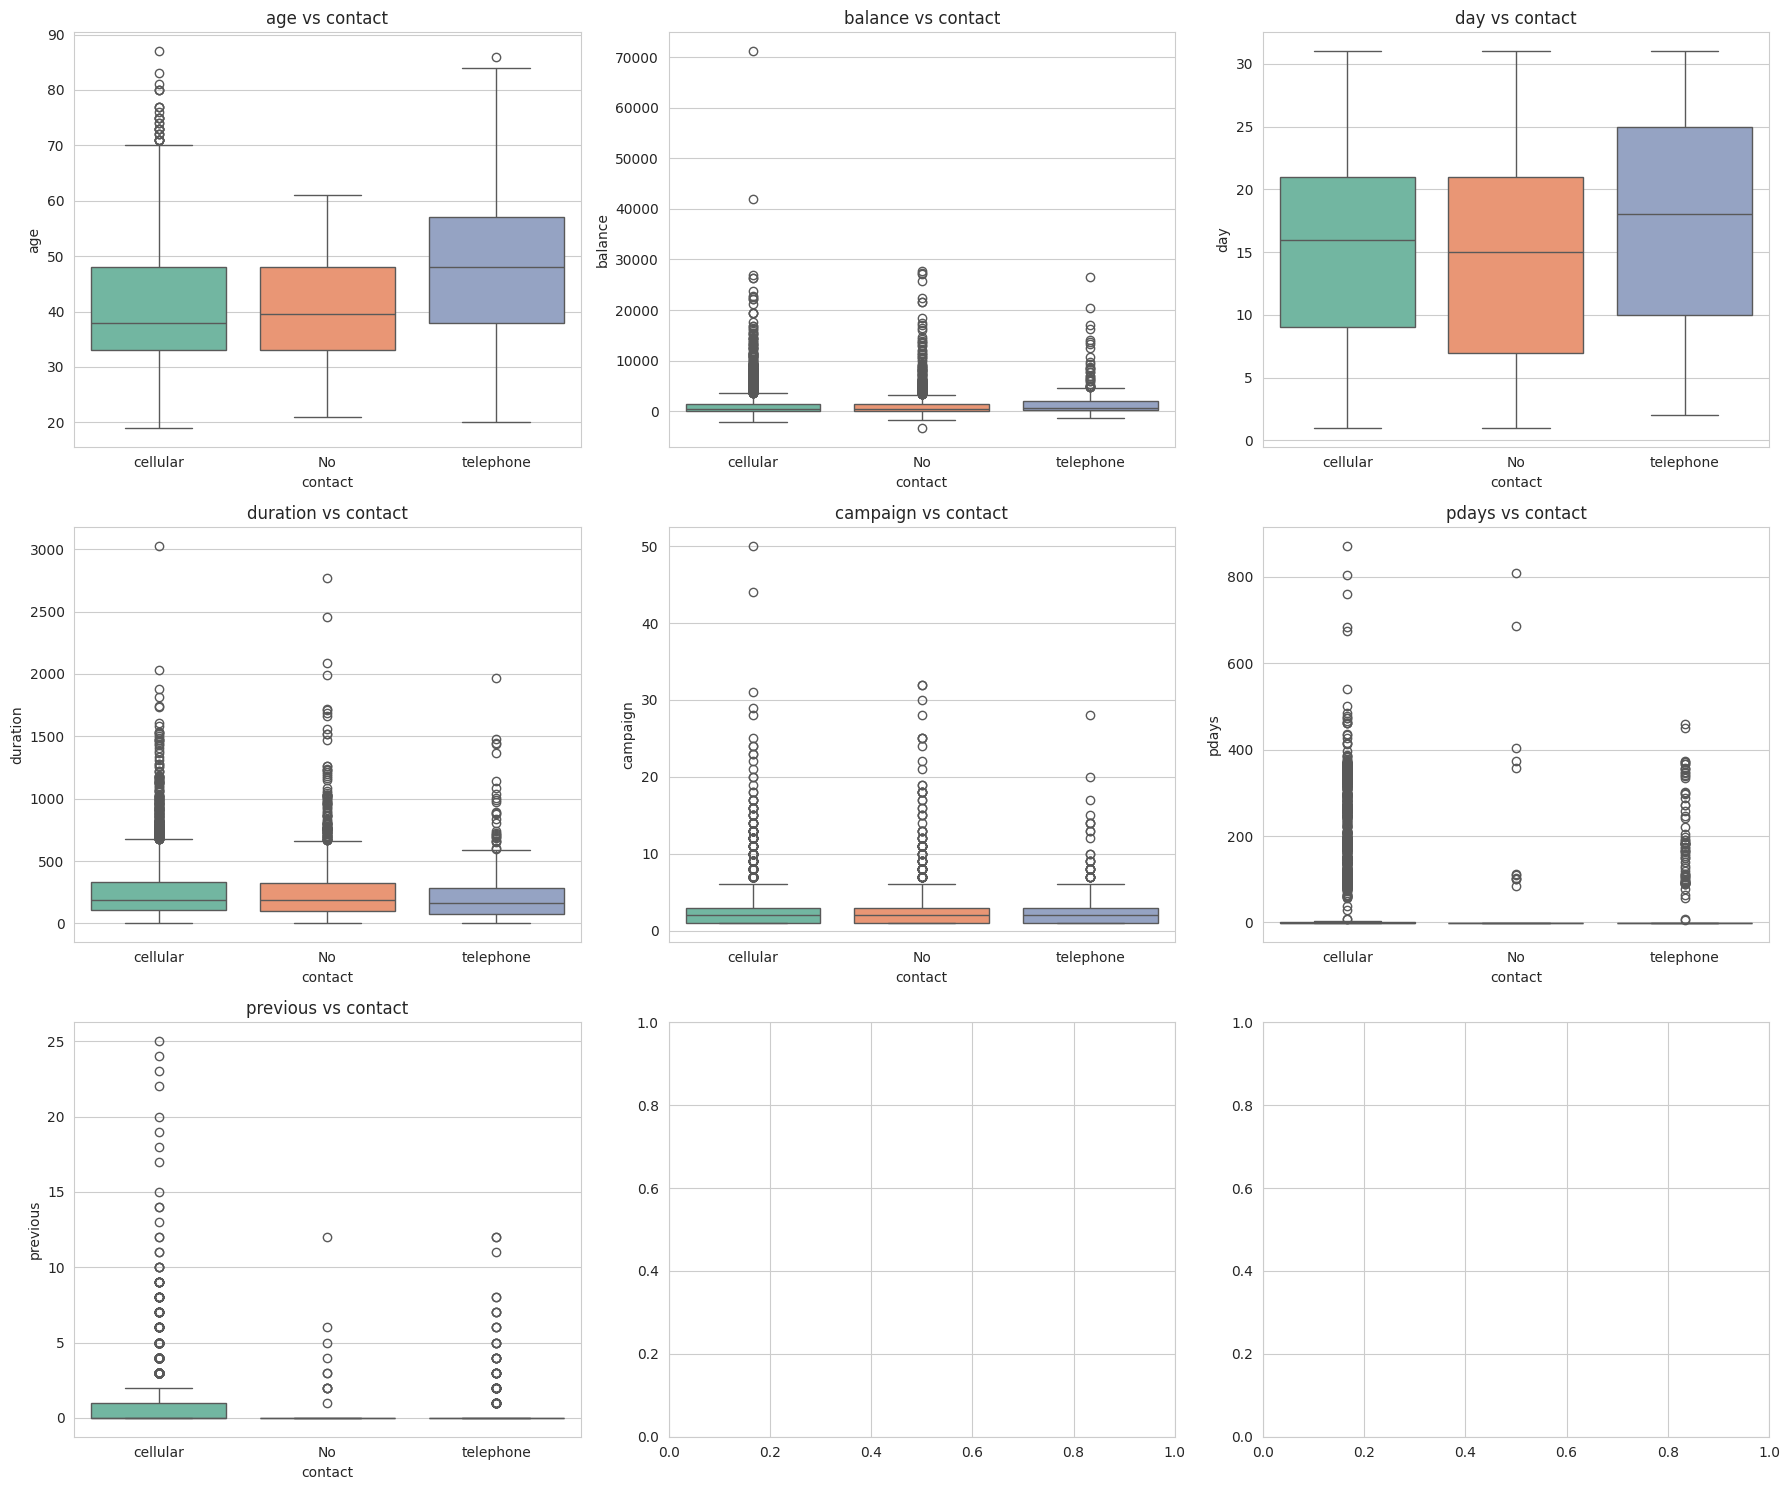

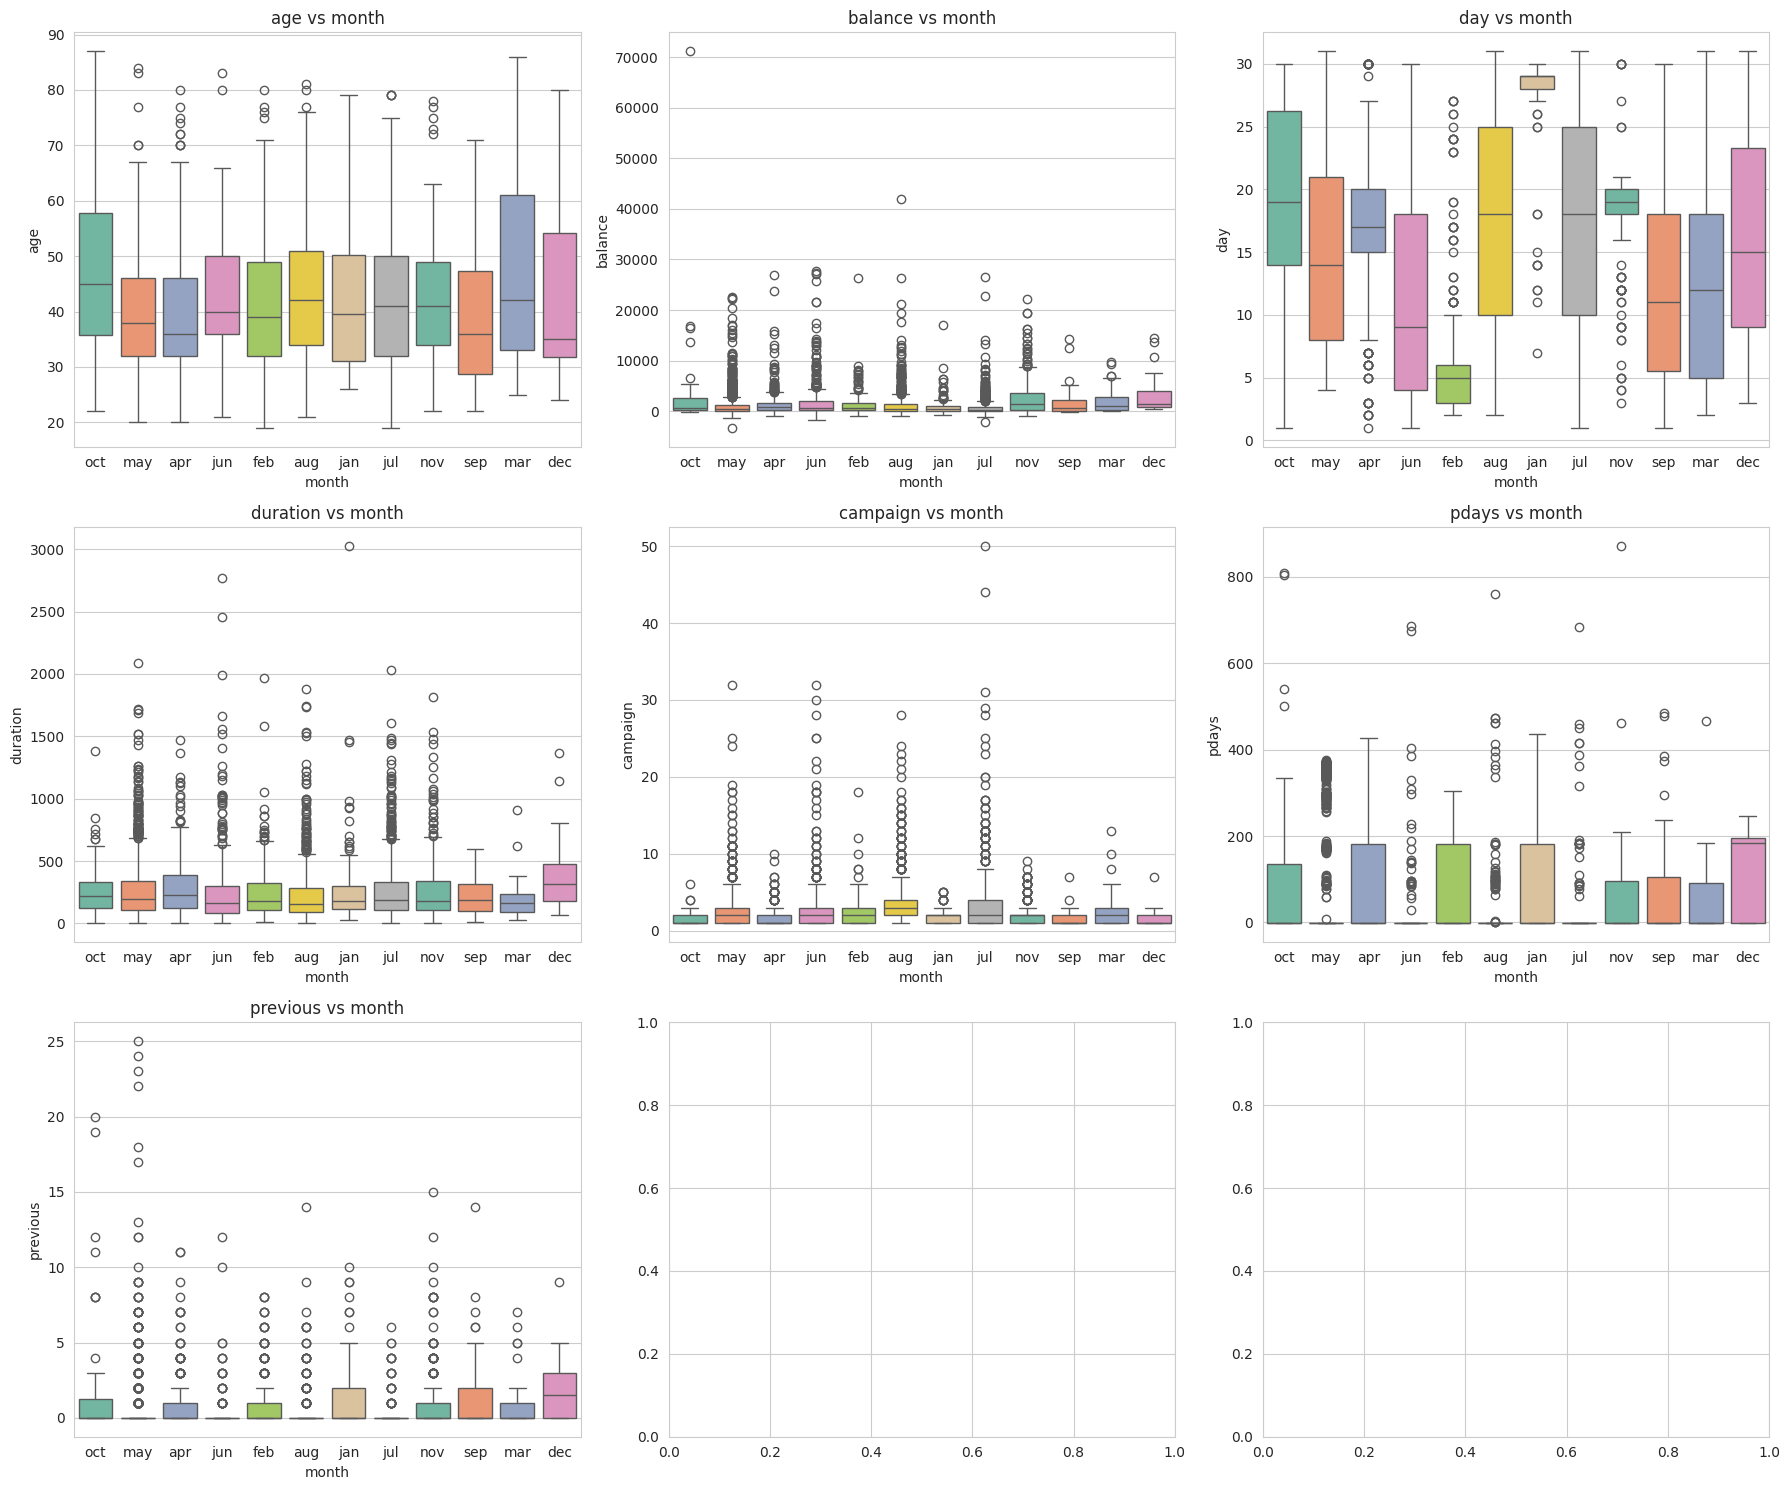

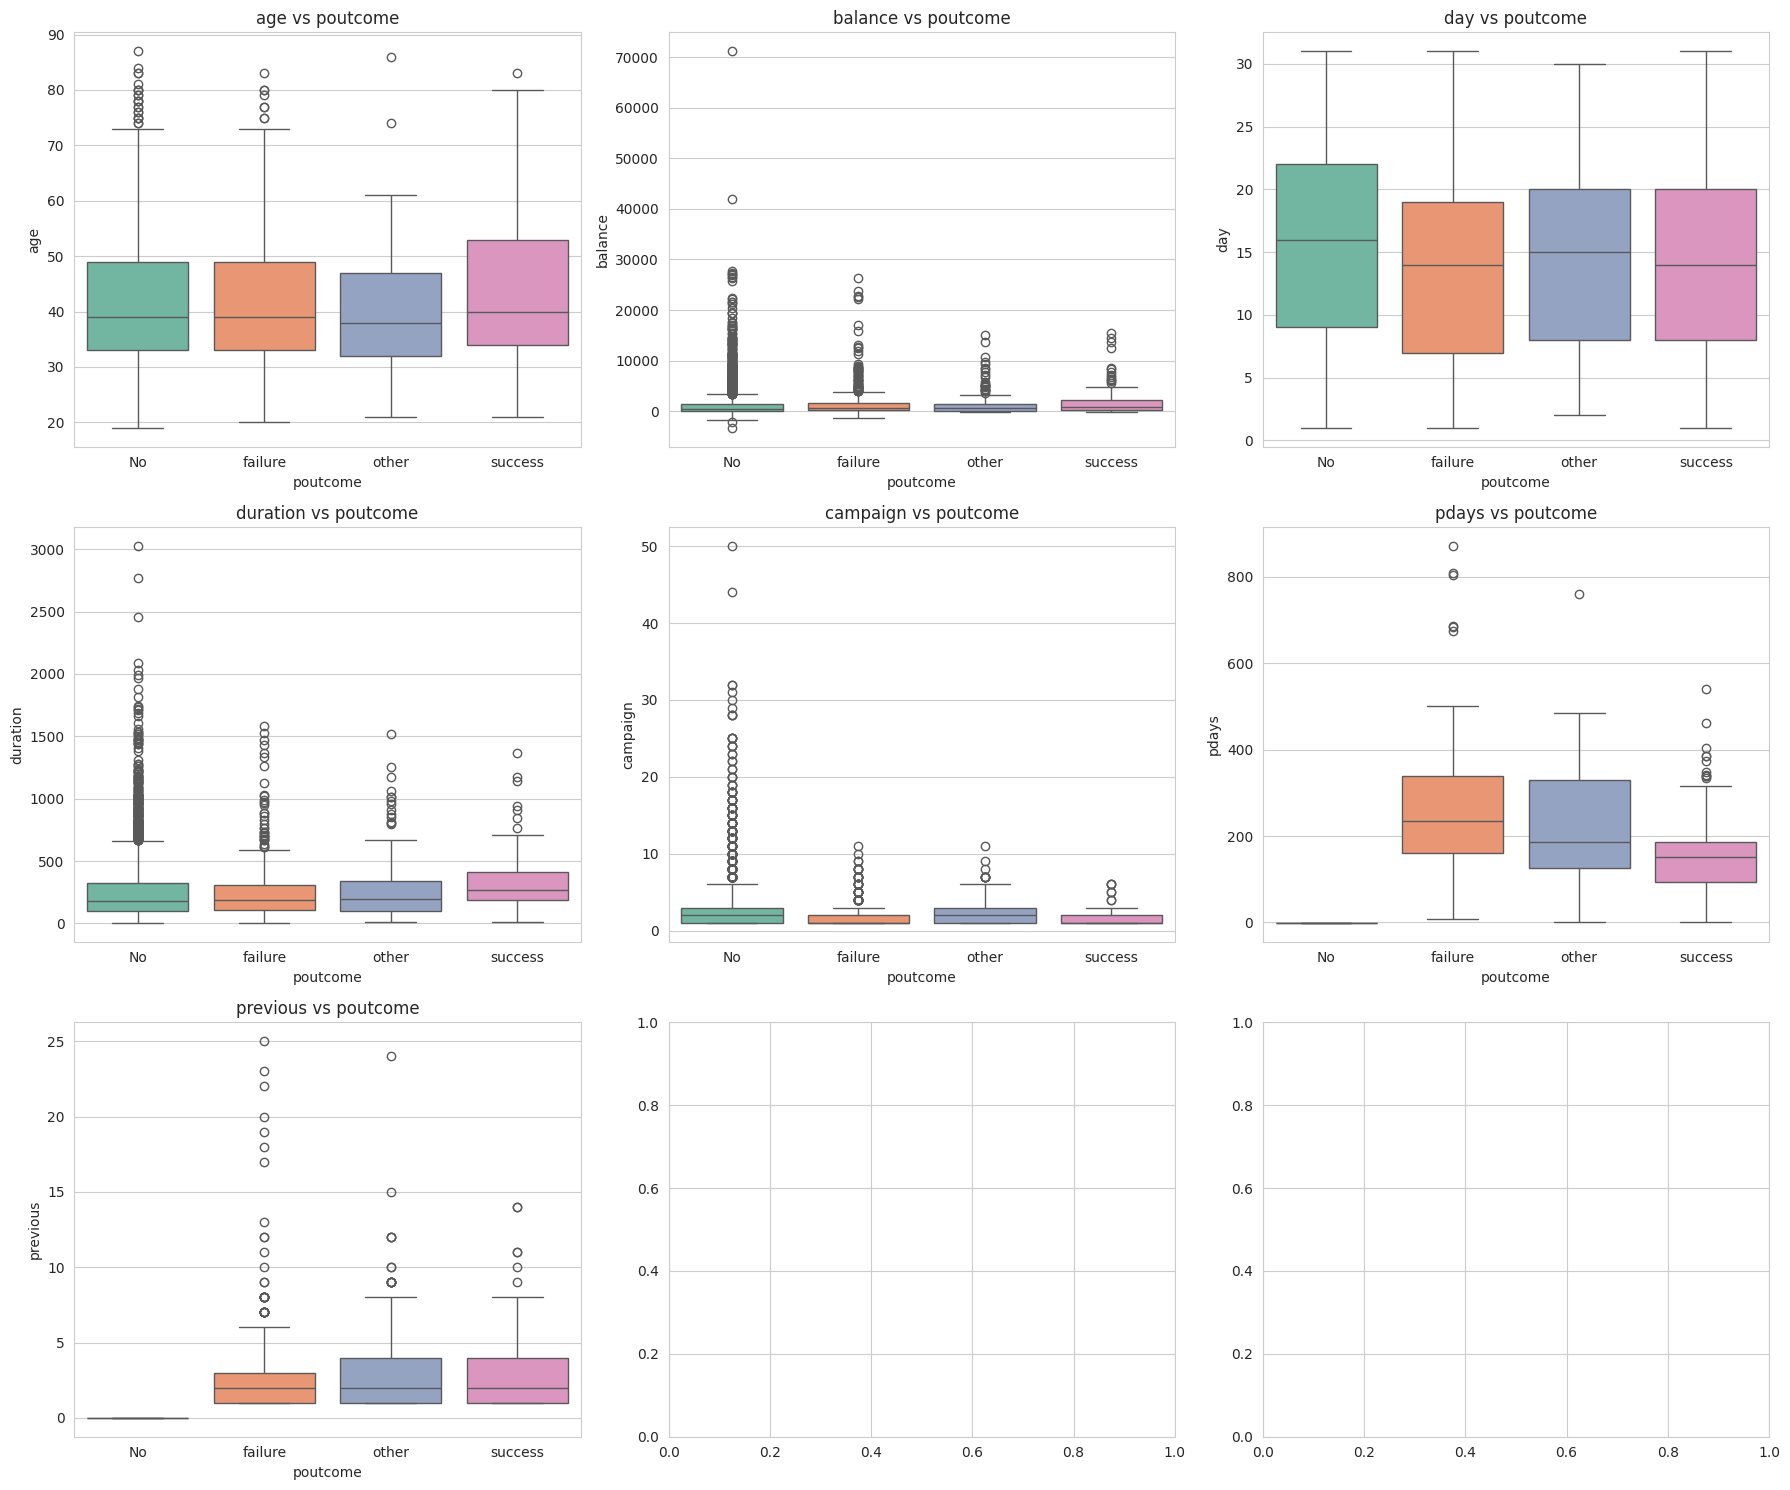

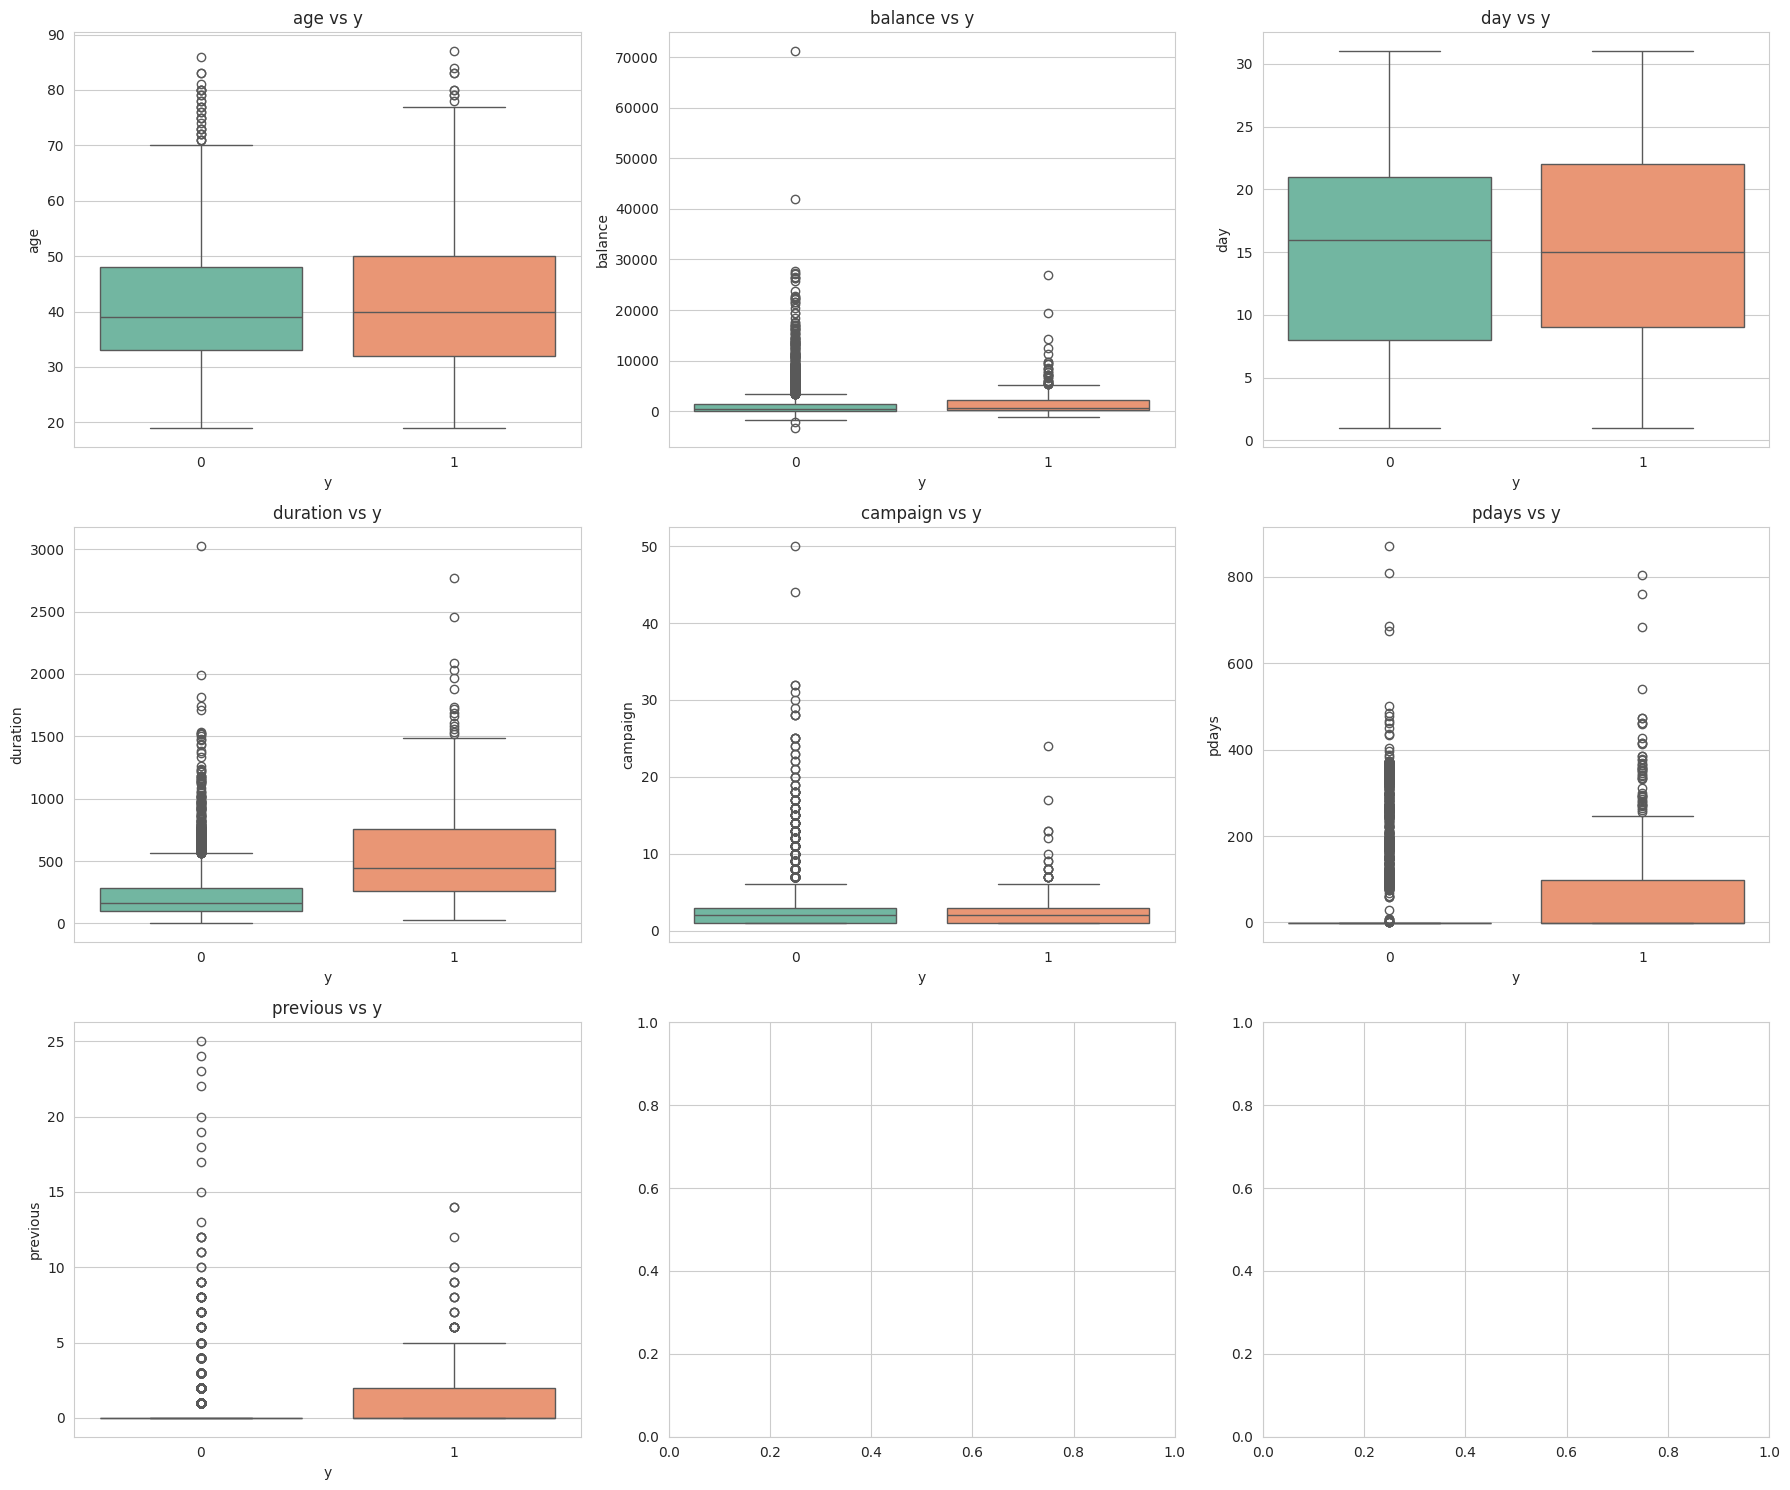

In [16]:
feature_columns = numerical_cols
target_columns = categorical_cols

sns.set_style("whitegrid")

for target in target_columns:

    n_cols = 3
    n_rows = math.ceil(len(feature_columns) / n_cols)

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(6*n_cols, 5*n_rows))
    axes = axes.flatten()

    for ax, feature in zip(axes, feature_columns):
        sns.boxplot(
            x=target,
            y=feature,
            hue=target,
            data=df,
            ax=ax,
            palette="Set2",
            legend=False
        )

        ax.set_title(f"{feature} vs {target}")
        ax.set_xlabel(target)
        ax.set_ylabel(feature)

    plt.tight_layout()
    plt.show()

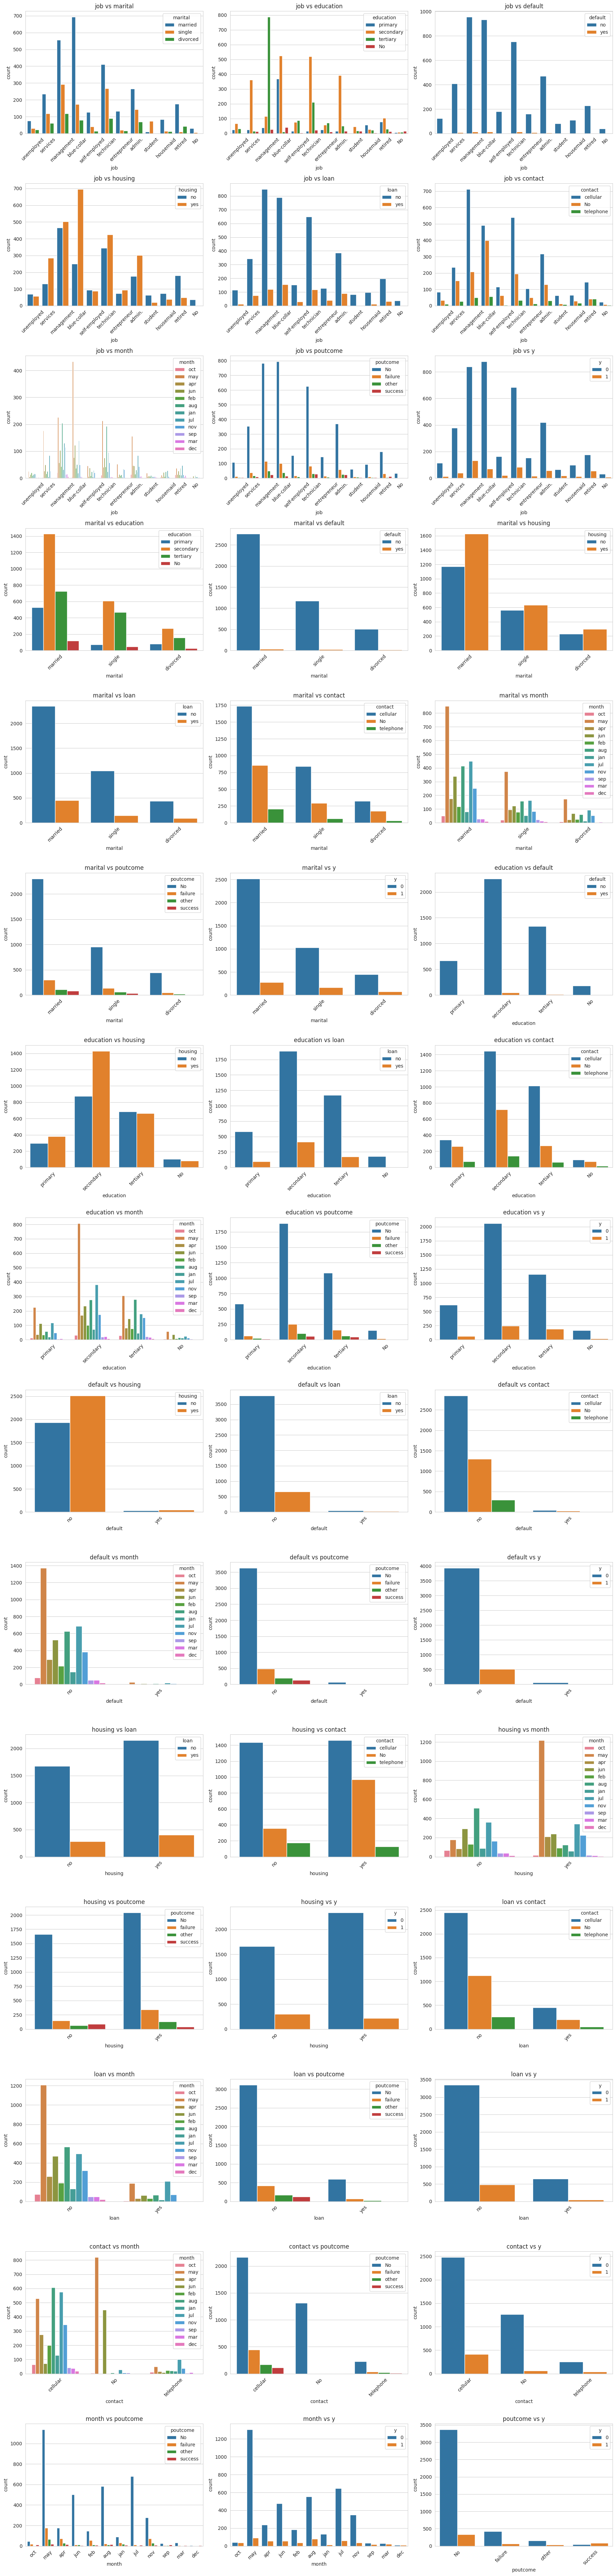

In [17]:
sns.set_style("whitegrid")

n_plots = len(categorical_cols) * (len(categorical_cols) - 1) // 2

n_cols = 3
n_rows = math.ceil(n_plots / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(6 * n_cols, 5 * n_rows))
axes = axes.flatten()

plot_idx = 0

for i in range(len(categorical_cols)):
    for j in range(i + 1, len(categorical_cols)):
        col1 = categorical_cols[i]
        col2 = categorical_cols[j]

        sns.countplot(
            data=df,
            x=col1,
            hue=col2,
            ax=axes[plot_idx]
        )

        axes[plot_idx].set_title(f"{col1} vs {col2}")
        axes[plot_idx].tick_params(axis='x', rotation=45)

        plot_idx += 1

for ax in axes[plot_idx:]:
    fig.delaxes(ax)

plt.tight_layout()
plt.show()

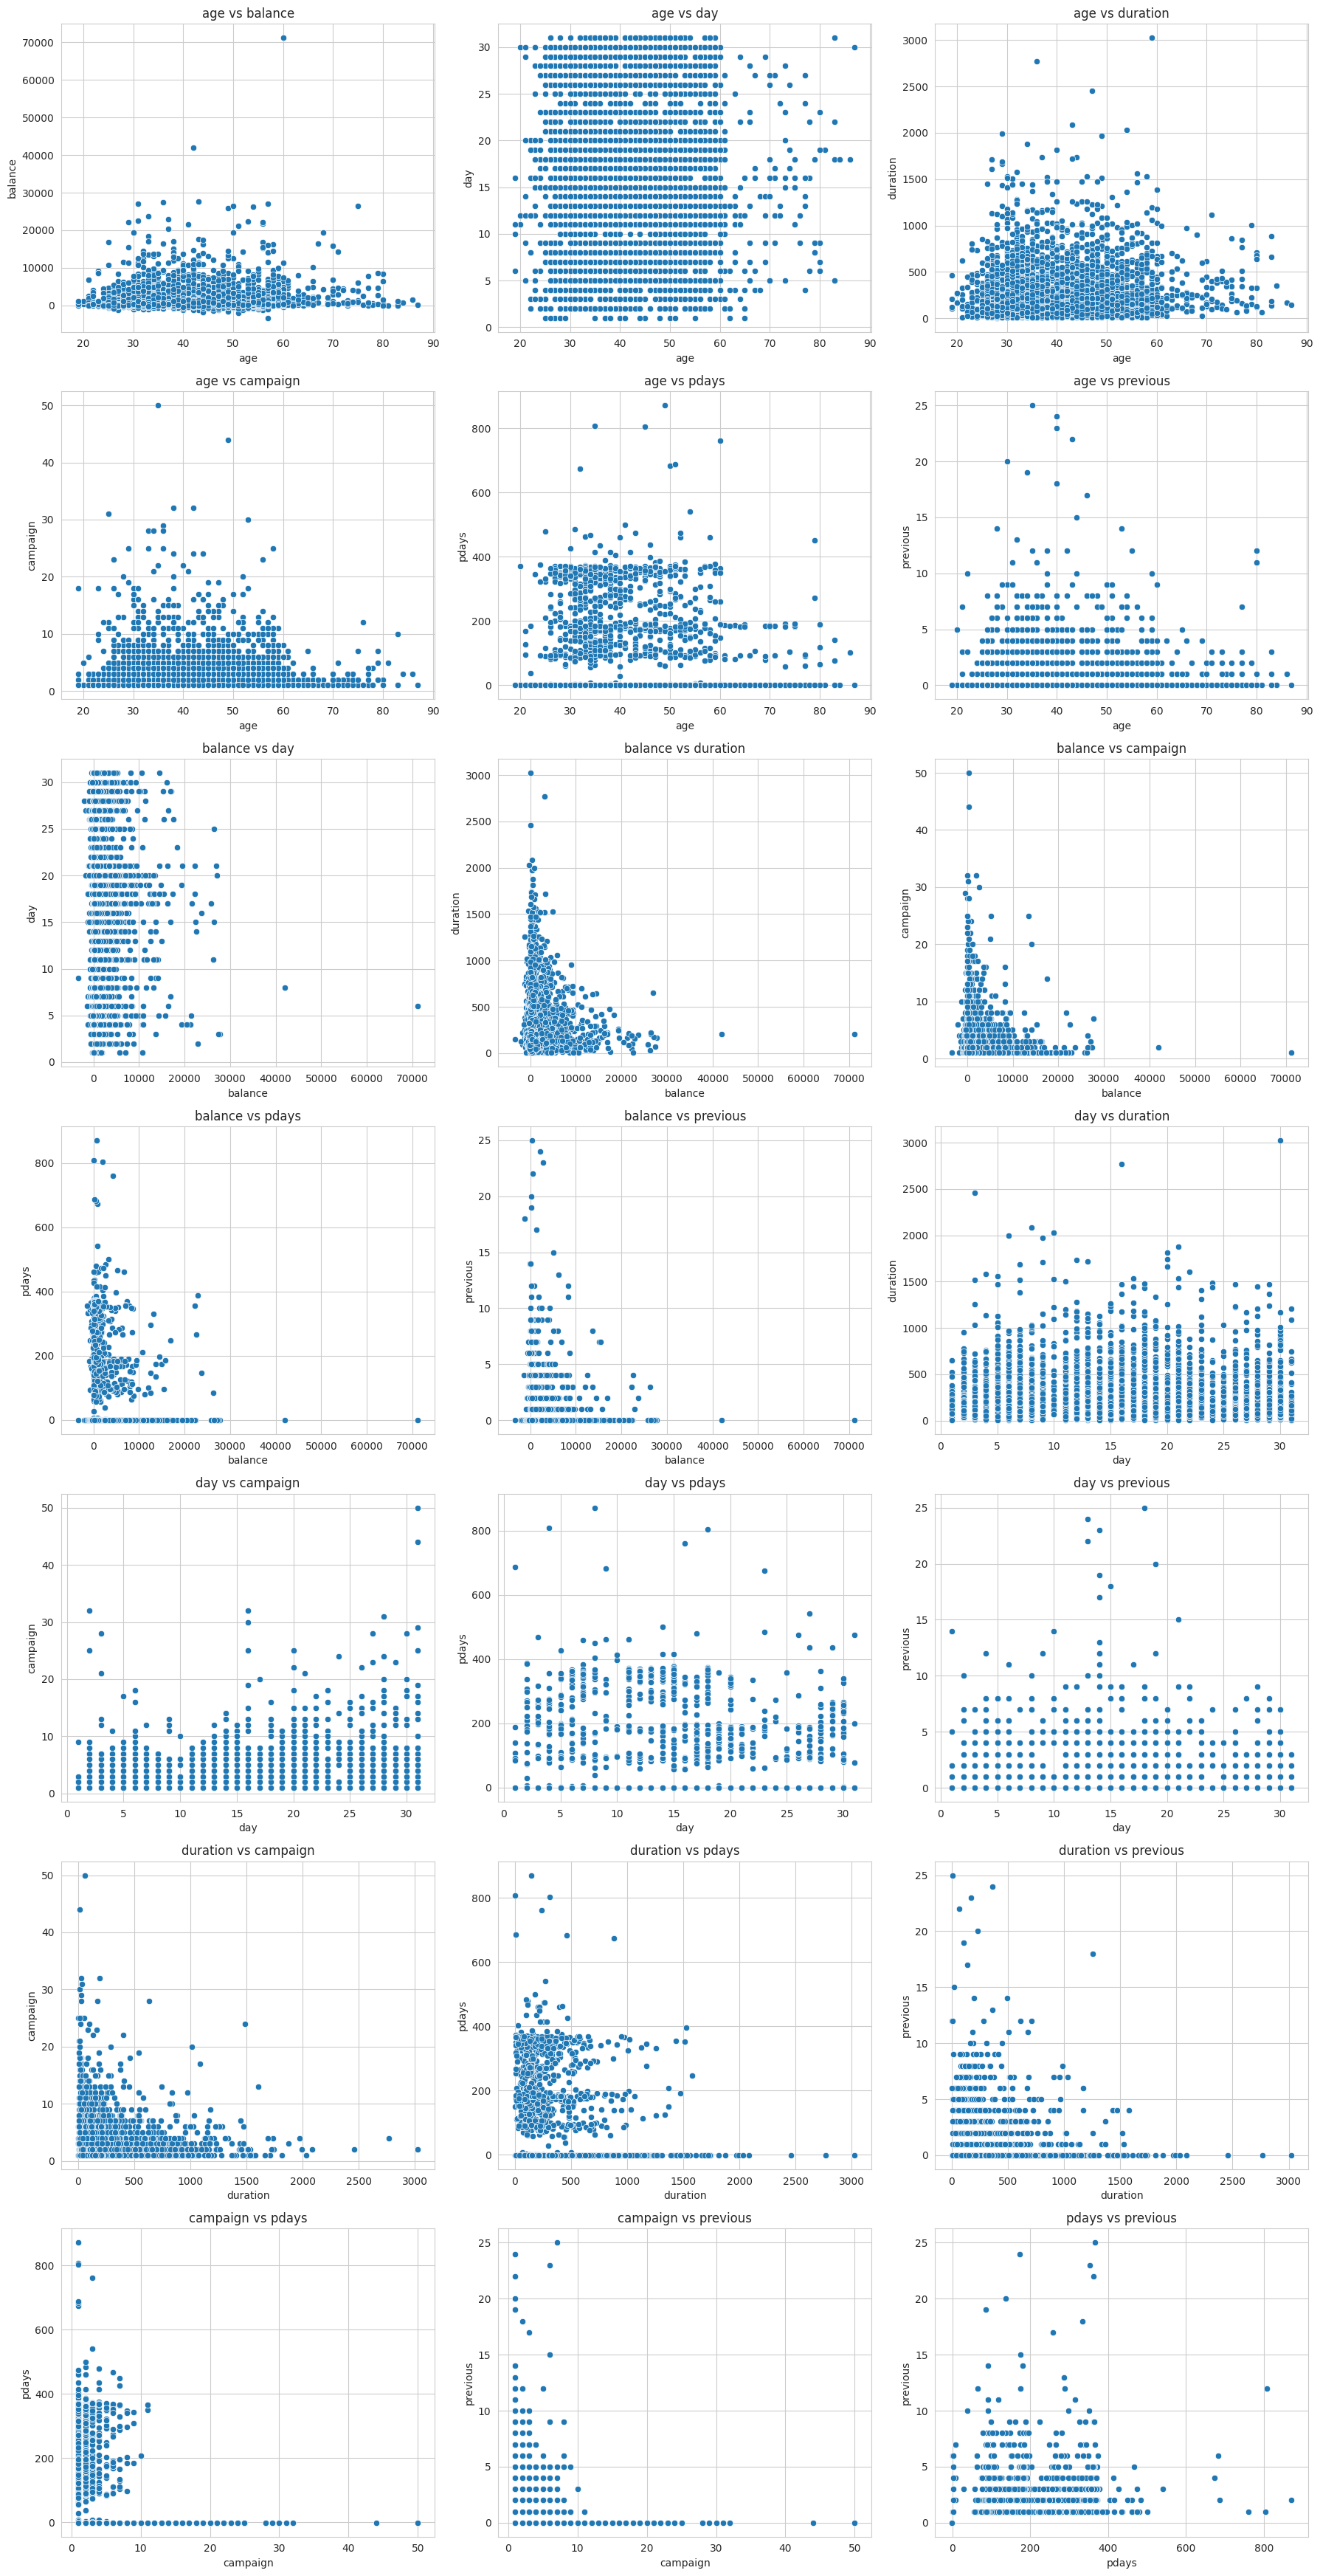

In [18]:
sns.set_style("whitegrid")

n_plots = len(numerical_cols) * (len(numerical_cols) - 1) // 2

if n_plots == 0:
    print("Need at least two numerical columns.")
else:
    n_cols = 3
    n_rows = math.ceil(n_plots / n_cols)

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(6 * n_cols, 5 * n_rows))

    if n_plots == 1:
        axes = [axes]
    else:
        axes = axes.flatten()

    plot_idx = 0

    for i in range(len(numerical_cols)):
        for j in range(i + 1, len(numerical_cols)):
            col1 = numerical_cols[i]
            col2 = numerical_cols[j]

            sns.scatterplot(
                data=df,
                x=col1,
                y=col2,
                ax=axes[plot_idx]
            )

            axes[plot_idx].set_title(f"{col1} vs {col2}")

            plot_idx += 1

    for ax in axes[plot_idx:]:
        fig.delaxes(ax)

    plt.tight_layout()
    plt.show()

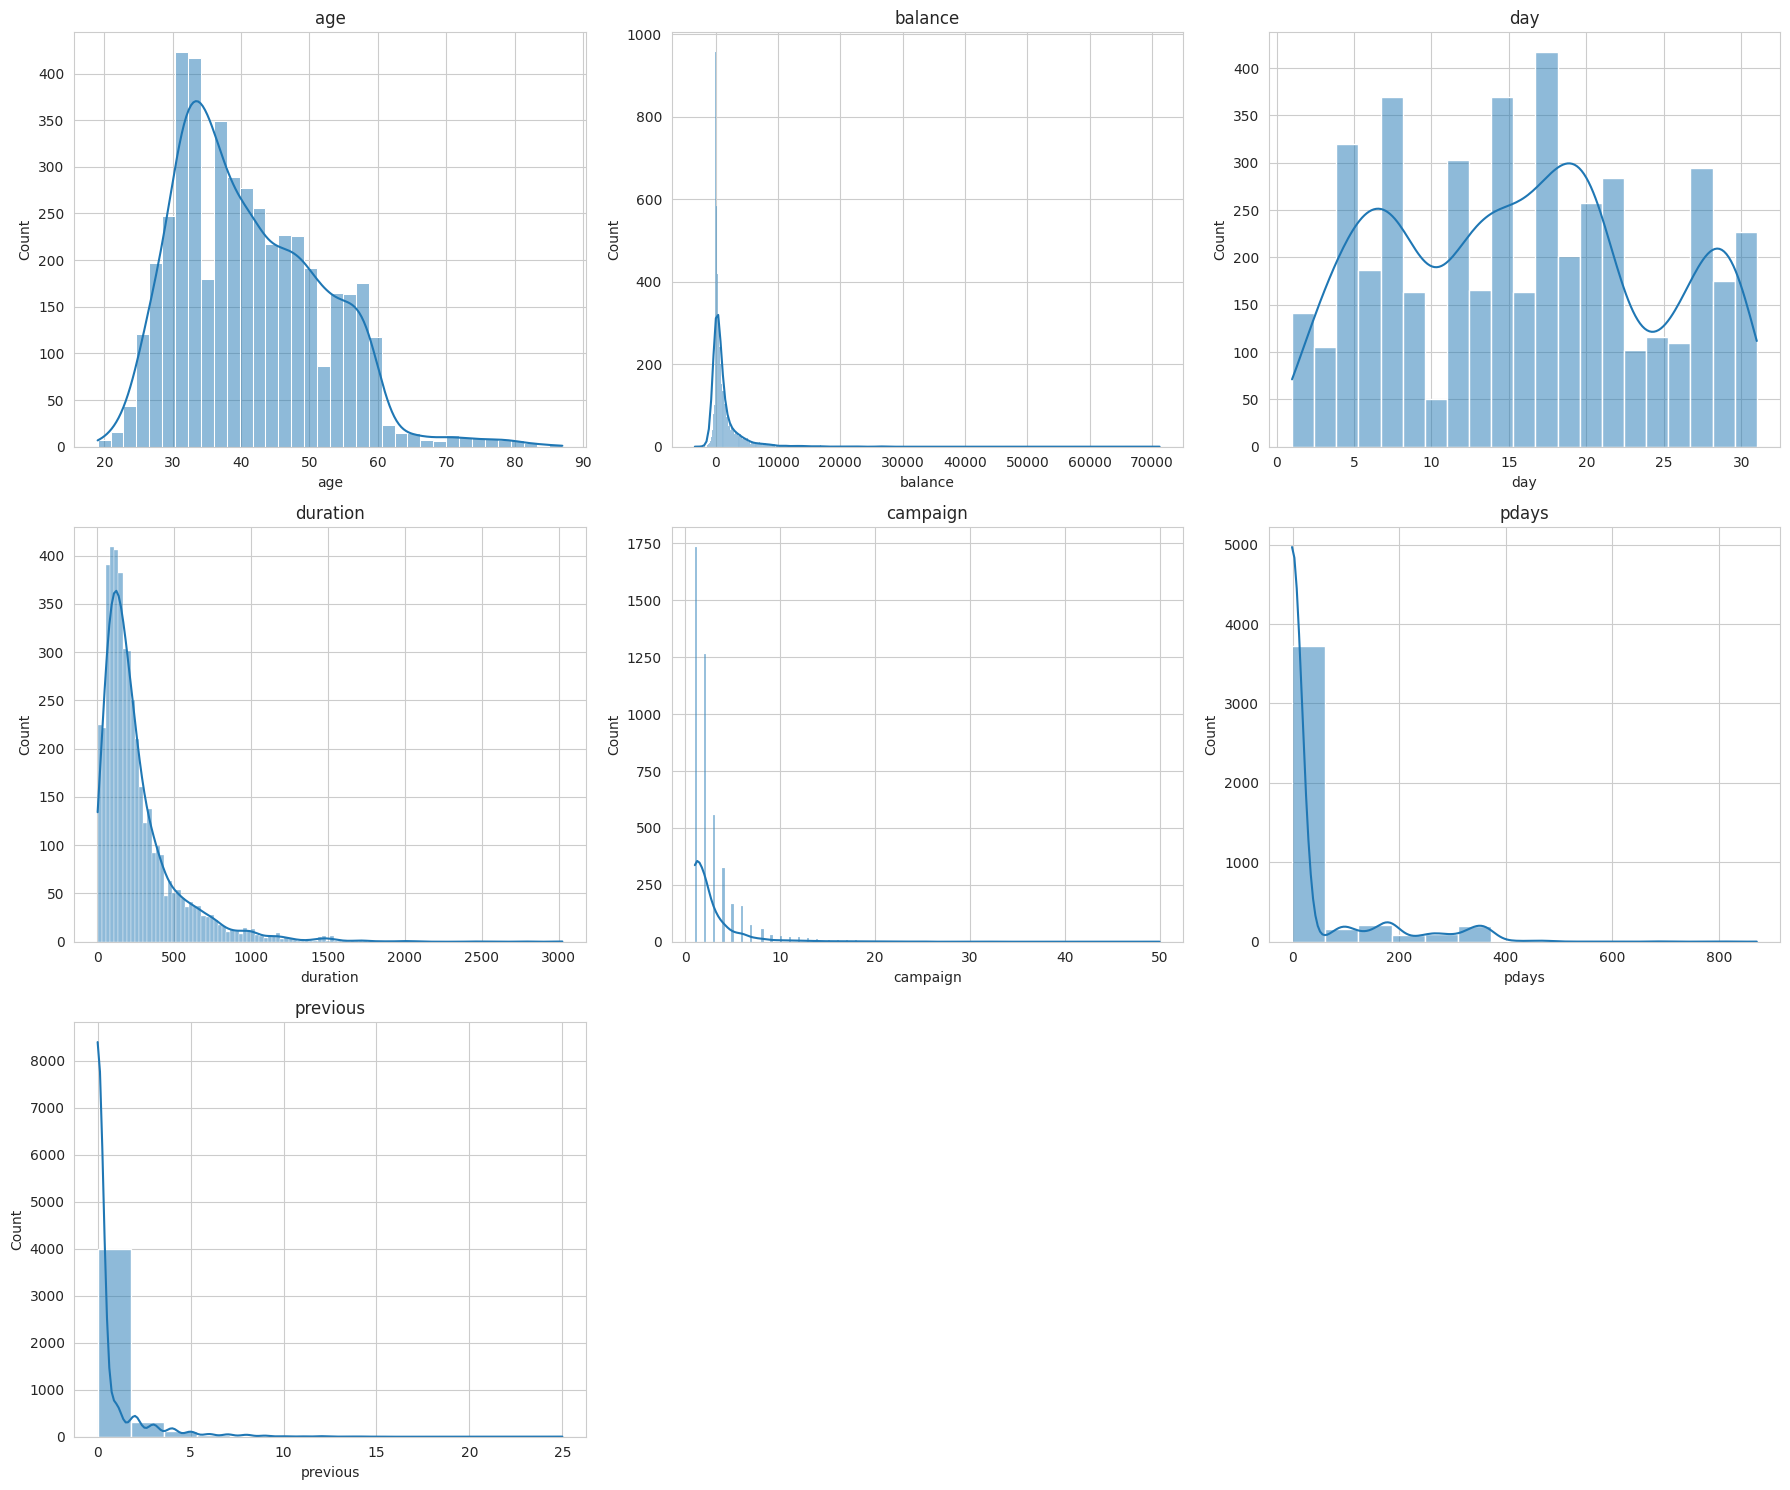

In [19]:
sns.set_style("whitegrid")

n_plots = len(numerical_cols)

if n_plots == 0:
    print("No numerical columns found.")
else:
    n_cols = 3
    n_rows = math.ceil(n_plots / n_cols)

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(6 * n_cols, 5 * n_rows))

    if n_plots == 1:
        axes = [axes]
    else:
        axes = axes.flatten()

    plot_idx = 0

    for col in numerical_cols:
        sns.histplot(
            data=df,
            x=col,
            kde=True,
            ax=axes[plot_idx]
        )

        axes[plot_idx].set_title(col)
        plot_idx += 1

    for ax in axes[plot_idx:]:
        fig.delaxes(ax)

    plt.tight_layout()
    plt.show()

## Model

### Separate Features and Target

In [20]:
X = df.drop("y", axis=1)
y = df["y"]

In [21]:
categorical_cols = X.select_dtypes(include=["object"]).columns
numerical_cols = X.select_dtypes(exclude=["object"]).columns

### Create the Preprocessing Pipeline

In [22]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols)
    ]
)

### Train-Test Split

In [23]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

### Select Model

In [24]:
X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)

In [25]:
model = Sequential([
    Dense(128, activation='relu', input_shape=(X_train.shape[1],)),
    Dense(64, activation='relu'),
    Dense(32, activation='relu'),
    Dense(1)
])

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [26]:
model.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)

In [27]:
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

In [28]:
history = model.fit(
    X_train, y_train,
    validation_split=0.2,
    epochs=20,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/20
91/91 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0885 - mae: 0.1857 - val_loss: 0.0772 - val_mae: 0.1712
Epoch 2/20
91/91 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0723 - mae: 0.1633 - val_loss: 0.0688 - val_mae: 0.1550
Epoch 3/20
91/91 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0645 - mae: 0.1511 - val_loss: 0.0660 - val_mae: 0.1500
Epoch 4/20
91/91 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0585 - mae: 0.1425 - val_loss: 0.0637 - val_mae: 0.1407
Epoch 5/20
91/91 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0531 - mae: 0.1328 - val_loss: 0.0683 - val_mae: 0.1438
Epoch 6/20
91/91 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0493 - mae: 0.1250 - val_loss: 0.0706 - val_mae: 0.1509
Epoch 7/20
91/91 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0422 - mae: 0.1154 - val_loss: 0.0712 - val_mae: 0.1480
Epoch 8/20
91/91 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0379 - mae: 0.1091 - val_loss: 0.0739 - val_mae: 0.1627
Epoch 9/20
91/91 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0345 - mae: 

### Evaluate

In [34]:
y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 
MAE: 0.1473664790391922
MSE: 0.08029313385486603
RMSE: 0.2833604309971066
R2 Score: 0.21057718992233276


### Save the Pipeline

In [37]:
pipeline_bundle = {
    "preprocessor": preprocessor,
    "model": model
}

with open("Model.pkl", "wb") as file:
    pickle.dump(pipeline_bundle, file)

## Key Insights



*   **Dataset Overview**: The dataset contains 4521 entries and 17 columns. There are 7 numerical and 10 categorical features.
*   **Data Quality**: No missing values were found, and no duplicate rows were present, indicating a clean dataset initially.
*   **Data Cleaning**: 'unknown' values in categorical columns were replaced with 'No'. The target variable 'y' was successfully mapped from 'yes'/'no' to 1/0 for model training.
*   **Numerical Feature Insights**:
    *   `balance`: Ranges from -3313 to 71188, with a mean of 1422.66, indicating potential outliers and some clients having negative balances.
    *   `duration`: Ranges from 4 to 3025 seconds. This feature is highly predictive but should not be used in a real-time predictive model as it's known after the call.
    *   `pdays`: The mean is 39.77, but the 25th, 50th, and 75th percentiles are -1, suggesting that for a large portion of the dataset, there was no previous contact (represented by -1).
*   **Categorical Feature Insights**:
    *   The `y` (target) column is imbalanced, with 'no' being the majority class (4000 entries) and 'yes' being the minority (521 entries). This imbalance needs to be considered for classification tasks.
    *   `job`, `education`, `contact`, and `poutcome` columns also contained 'unknown' values which were handled during cleaning.
*   **Model Performance**: The model achieved an MAE of 0.147, MSE of 0.080, RMSE of 0.283, and a low R2 Score of 0.211. This suggests the current model does not explain a significant portion of the variance in the target variable, indicating room for improvement.

## Conclusions

*   The initial data cleaning and preprocessing steps were successful in preparing the dataset for model training.
*   The current neural network model, while able to learn, shows relatively low predictive power (R2 score of 0.211) for directly predicting the subscription outcome. The `mae` and `rmse` values also suggest that the predictions are not very close to the actual values.
*   **Recommendations for Improvement**:
    *   **Feature Engineering**: Create new features from existing ones (e.g., age groups, duration categories, or more meaningful `pdays` handling).
    *   **Model Selection**: Explore other machine learning models more suitable for imbalanced binary classification, such as Logistic Regression, Random Forest, Gradient Boosting, or SVM, which might perform better than a simple dense neural network for this problem.
    *   **Handle Imbalance**: Address the class imbalance in the target variable `y` using techniques like SMOTE (Synthetic Minority Over-sampling Technique), undersampling, or class weighting during model training.
    *   **Hyperparameter Tuning**: Optimize the current model's hyperparameters (e.g., number of layers, neurons, activation functions, learning rate) for better performance.
    *   **Feature Importance**: Analyze feature importance to understand which features contribute most to the predictions and potentially focus on them.
    *   **Remove `duration`**: For a real-world predictive model, the `duration` feature should be excluded as it is only known after the marketing call, making it unsuitable for predicting future outcomes.